<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/01_global_characteristics_and_summary_statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 01 · Global characteristics and summary statistics

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

Before we ask a model to forecast a series, it helps to know what kind of series it is. This notebook describes
every series in the Chapter 3 data in two tables. The first holds the familiar summary statistics: the typical
level, the spread, the range and so on. The second records what we call the *global characteristics* of each
series: whether it trends or wanders, whether it repeats a seasonal pattern, how long it remembers its own past,
whether it behaves non-linearly, and whether its behaviour has changed over time. For the five metal prices we
also measure how closely they move together.

This matters even though every model in this chapter is used zero-shot. A zero-shot model is never trained on our
data. It does well when our series resemble the ones it saw during pre-training and less well when they do not.
Trends, unit roots, seasonality, long memory, non-linearity and sudden breaks each favour different models and
different baselines. By writing these properties down now, before any forecast is made, we can explain the
results later in the chapter instead of just reporting them.

The notebook covers D1 (daily temperature in central England), the D2 covariates, D3 and D4 (five monthly metal
prices and three economic drivers), B1 (the WTI crude oil price) and B2 (US Treasury yields). Seventeen series in
all go into the characteristics table.

**What you will learn**

- how to compute and read the summary statistics and global characteristics of a time series
- the idea and the formulas behind the KPSS, ADF, QS, Kruskal–Wallis, Keenan, Tsay, BDS, rescaled-range and
  CUSUM tests
- why, with 10,000 observations, a p-value on its own says little, and what to read next to it
- how strongly five metal prices move together, and whether they share a long-run equilibrium

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 (Google Colab runs 3.13) |
| Packages | [`requirements-dataprep.txt`](requirements-dataprep.txt) (pinned versions); on Colab the setup cell adds the few that Colab lacks ([`requirements-colab.txt`](requirements-colab.txt)) |
| Hardware | CPU only (Colab free tier is enough) |
| Network | none: reads the frozen datasets in `input_timeseries/` |
| Run time | under 1 minute on 4 CPU cores (Colab's free tier has 2: allow up to twice as long) |
| Peak memory | 0.8 GB (kernel peak) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. The first code cell fetches this chapter's folder and installs the
  packages Colab does not have (about a minute). If it says it is restarting the session, wait, then choose
  *Runtime > Run all* again. To use your own copy on Google Drive, set `DRIVE_COPY` in that cell to the folder's path.
- **Your own computer (Cursor, VS Code or Jupyter):** create an environment with
  `uv venv .venv-dataprep -p 3.12 && uv pip install -p .venv-dataprep -r requirements-dataprep.txt` (or
  `python -m venv .venv-dataprep` and `pip install -r ...`), open this folder, choose that environment's kernel and run
  all cells.

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/v3  |  Python 3.12.3  |  Colab: False


## Load the data

Notebook 00 downloaded the six datasets and saved them as CSV files in `input_timeseries/`, together with a small
manifest file that records the cut-off date of the data. The next cells read them back. Every number quoted in
the text of this notebook comes from the data that end on 30 September 2026 and were downloaded on 1 November
2026. If you rebuild the data later, the printed tables will update but the text will not.

`SERIES` lists the 17 series that the two tables describe. Some of the tests need the length of the repeating
cycle, the *seasonal period*, and that depends on how often a series is recorded:

- daily data (temperature and the two climate indices): 7 days for a week and 365 days for a year;
- trading-day data (oil and Treasury yields), which skip weekends and holidays: 5 days for a week and 252 days
  for a year;
- monthly data (metals and their drivers): 12 months for a year.

In [2]:
from pathlib import Path

FRED_CSV = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={series}"
HADCET_PAGE = "https://www.metoffice.gov.uk/hadobs/hadcet/data/download.html"
HADCET_FILE = "meantemp_daily_totals.txt"
CPC_NAO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.nao.cdas.z500.19500101_current.csv"
CPC_AO = "https://ftp.cpc.ncep.noaa.gov/cwlinks/norm.daily.ao.cdas.z1000.19500101_current.csv"
PINK_SHEET_PAGE = "https://www.worldbank.org/en/research/commodity-markets"
# direct link to the same workbook (checked 1 Nov 2026: "Updated on October 02, 2026"); used if the page is unreachable
PINK_SHEET_URL = ("https://thedocs.worldbank.org/en/doc/74e8be41ceb20fa0da750cda2f6b9e4e-0050012026/related/"
                  "CMO-Historical-Data-Monthly.xlsx")

N_DAILY = 10_000            # most recent observations kept for daily data
MONTHLY_START = "1982-01-01"  # first month of the Cleveland Fed real-rate series
HORIZONS = {"daily": [7, 14, 30, 60, 90], "monthly": [3, 6, 9, 12, 24]}
ROLLING_WINDOWS = {"daily": {7: 5, 14: 5, 30: 5, 60: 5, 90: 5},
                   "monthly": {3: 3, 6: 3, 9: 3, 12: 3, 24: 1}}
HADCET_LAT = 52.5           # latitude used for day length (degrees north)

METALS = {  # column: (World Bank Pink Sheet column, FRED id of the IMF series used as a cross-check, description)
    "copper": ("Copper", "PCOPPUSDM", "Copper (LME), grade A cathodes, USD per metric ton"),
    "aluminium": ("Aluminum", "PALUMUSDM", "Aluminium (LME), primary ingots 99.7 %, USD per metric ton"),
    "nickel": ("Nickel", "PNICKUSDM", "Nickel (LME), cathodes 99.8 %, USD per metric ton"),
    "zinc": ("Zinc", "PZINCUSDM", "Zinc (LME), high grade 99.95 %, USD per metric ton"),
    "lead": ("Lead", "PLEADUSDM", "Lead (LME), refined 99.97 %, USD per metric ton"),
}
DRIVERS = {  # column: (FRED id, fallback FRED id, description)
    "global_activity": ("IGREA", None, "Kilian index of global real economic activity (% deviation from trend)"),
    "usd": ("NNUSBIS", "TWEXBGSMTH", "US dollar nominal effective exchange rate, BIS narrow index (2020 = 100)"),
    "real_rate_10y": ("REAINTRATREARAT10Y", "DFII10", "US 10-year real interest rate, Cleveland Fed (%)"),
}
TREASURY = {"y3m": "DGS3MO", "y1": "DGS1", "y2": "DGS2", "y5": "DGS5", "y10": "DGS10"}
WTI = "DCOILWTICO"

DATASETS = {
    "D1": {"name": "Central England Temperature, daily mean", "kind": "U", "grain": "daily",
           "targets": ["temp"], "covariates": []},
    "D2": {"name": "Central England Temperature + covariates", "kind": "U+X", "grain": "daily",
           "targets": ["temp"],
           "known_future": ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2",
                            "fourier_sin_3", "fourier_cos_3", "daylength_h"],
           "past_only": ["wav_d1_2", "wav_d3_4", "wav_d5_6", "wav_d7_8", "wav_s8", "nao", "ao"]},
    "D3": {"name": "Base-metal prices, monthly", "kind": "MV", "grain": "monthly",
           "targets": list(METALS), "covariates": []},
    "D4": {"name": "Base metals + global drivers", "kind": "MV+X", "grain": "monthly",
           "targets": list(METALS), "known_future": [], "past_only": list(DRIVERS)},
    "B1": {"name": "WTI crude oil, daily spot", "kind": "U", "grain": "trading day",
           "targets": ["wti"], "covariates": []},
    "B2": {"name": "US Treasury yield curve, daily", "kind": "MV", "grain": "trading day",
           "targets": list(TREASURY), "covariates": []},
}


def find_root(start=None):
    """The chapter folder: the one that holds src/ch03_dataprep and data/."""
    here = Path(start or Path.cwd()).resolve()
    for p in [here, *here.parents]:
        if (p / "src" / "ch03_dataprep").is_dir() and (p / "data").is_dir():
            return p
    raise FileNotFoundError("Run the notebook from inside the Chapter 3 folder.")


def grain_key(dataset_id):
    """'daily' for daily and trading-day data, 'monthly' otherwise."""
    return "monthly" if DATASETS[dataset_id]["grain"] == "monthly" else "daily"

In [3]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ch03_dataprep.plotting import DIVERGING, INK, INK_2, SERIES as COLORS, set_style

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 160)

SNAP = {name: pd.read_csv(INPUT / f"{name}.csv", index_col=0, parse_dates=True) for name in DATASETS}
manifest = json.loads((INPUT / "snapshot_manifest.json").read_text())
PERIODS = {"daily": [7, 365], "trading day": [5, 252], "monthly": [12]}
SERIES = ([("D1", "temp"), ("D2", "nao"), ("D2", "ao")] + [("D3", m) for m in METALS]
          + [("D4", d) for d in DRIVERS] + [("B1", "wti")] + [("B2", c) for c in TREASURY])
print(f"snapshot vintage: {manifest['vintage_cut']}  |  {len(SERIES)} series")
for name, frame in SNAP.items():
    print(f"  {name}: {frame.index[0].date()} to {frame.index[-1].date()}, {len(frame):,} rows, {frame.shape[1]} columns")

snapshot vintage: 2026-09-30  |  17 series
  D1: 1999-05-16 to 2026-09-30, 10,000 rows, 1 columns
  D2: 1999-05-16 to 2026-09-30, 10,000 rows, 13 columns
  D3: 1982-01-01 to 2026-07-01, 535 rows, 5 columns
  D4: 1982-01-01 to 2026-07-01, 535 rows, 8 columns
  B1: 1986-01-02 to 2026-09-30, 9,513 rows, 1 columns
  B2: 1986-10-08 to 2026-09-30, 10,000 rows, 5 columns


D4's five targets are the same five metal prices as D3, over the same months, so only its three drivers (the
Kilian index of global economic activity, the US dollar index and the US real interest rate) add new rows to the
tables.

D2 adds two kinds of covariates to the temperature. The North Atlantic Oscillation (NAO) and Arctic Oscillation
(AO) indices are measured series, so they get the full set of tests. The others (Fourier terms, day length and
wavelet bands) are calculated, either from the calendar or from the temperature itself. Testing a calendar sine
wave for stationarity or non-linearity would tell us nothing, so Section 1b instead shows how each one is built,
checks it against its formula and summarises it.

## 1 · Summary statistics (Table 1)

The first table answers plain questions about each series, one row per series. Where does it usually sit? How
far does it stray from that level? What are its lowest and highest values? Is its spread large or small compared
with its level?

These numbers matter for forecasting in two ways. First, they show the *scale* of each series, and scale decides
how forecast errors can be compared. An error of 100 is negligible for a nickel price quoted in thousands of
dollars per tonne and absurd for a bond yield quoted in percent, so error measures that depend on scale, such as
the mean absolute error (MAE), cannot be averaged across series. Second, a gap between the mean and the median is
a first hint of a lopsided (skewed) distribution or of occasional extreme values.

For a series $x_1, \dots, x_n$, the mean $\bar x$ is the average value and the standard deviation $s$, the square
root of the variance $s^2$, measures the typical distance of the values from it:

$$\bar x = \frac{1}{n}\sum_{t=1}^{n} x_t, \qquad s^2 = \frac{1}{n-1}\sum_{t=1}^{n} \left(x_t - \bar x\right)^2, \qquad s = \sqrt{s^2}.$$

We divide by $n - 1$ rather than $n$ because the deviations are measured from $\bar x$, which was itself
estimated from the same data; dividing by $n$ would understate the spread slightly.

The median is the middle value once the data are sorted, and the quartiles $Q_1$ and $Q_3$ mark the points below
which a quarter and three quarters of the values fall. Together with the minimum and the maximum they describe the
spread without being pulled about by a few extreme values, as the mean and the standard deviation can be. The
quartiles follow R's `quantile(type = 1)`, which always returns one of the observed values. With the sorted
values written $x_{(1)} \le x_{(2)} \le \dots \le x_{(n)}$,

$$Q_p = x_{(\lceil np \rceil)},$$

the smallest observation with at least a share $p$ of the data at or below it ($p = 0.25$ for $Q_1$ and
$p = 0.75$ for $Q_3$).

The coefficient of variation expresses the standard deviation as a percentage of the mean,

$$\mathrm{CoV} = 100 \times \frac{s}{\bar x},$$

so that variability can be compared across series measured in different units. It only makes sense for a series
that stays above zero, such as a price. When the mean is close to zero the ratio explodes, and for a series that
takes both signs, or a temperature in °C whose zero point is arbitrary, it has no meaning.

Entropy comes from information theory. It is high when the values are spread evenly over many possibilities and
low when a few values dominate. The table gives it in two versions, and only the second one describes the data.

The first, `entropy_mm`, is what the R function `entropy::entropy(x, method = "MM")` returns when it is handed
the raw series. That function expects a vector of counts, so it treats each observation as the count of its own
category, turns the values into shares $p_t$ of their total, and adds the Miller–Madow correction for small
samples:

$$\hat H_{\mathrm{MM}} = -\sum_{t:\thinspace p_t > 0} p_t \log p_t + \frac{m - 1}{2 \sum_u x_u}, \qquad p_t = \frac{x_t}{\sum_u x_u}, \qquad m = \lvert\lbrace t : x_t > 0\rbrace\rvert. \tag{1}$$

Here $m$ is the number of positive values. When all values are positive and of similar size, every share is close to $1/n$, so the result is close to
$\log n$ whatever the values are. It reflects the length of the series much more than its information content.
Negative values give negative shares, which the R code skips in the sum but keeps in the total, so for a series
that goes below zero this column should not be read at all. We keep it only because two earlier studies by the
authors of this book report it in the same kind of table (see References), and a comparison needs the same
calculation.

The second, `entropy_hist`, is the ordinary entropy of a histogram of the values. The values are sorted into bins
of equal width $h = 2\thinspace\mathrm{IQR}\thinspace n^{-1/3}$ (the Freedman–Diaconis rule, with IQR the interquartile range), and
with $\hat\pi_b$ the share of values that fall in bin $b$,

$$\hat H = -\sum_b \hat\pi_b \log \hat\pi_b.$$

It is larger for a series whose values spread over many bins and smaller for one that stays in a few, so it does
describe the shape of the distribution.

In [4]:
import warnings

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from scipy.special import gammaln
from statsmodels.stats.diagnostic import breaks_cusumolsresid
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, bds, kpss

In [5]:
def r_quantile_type1(x, q):
    """Quantile as R's quantile(type = 1): an observed value, x_(ceil(n q))."""
    x = np.sort(np.asarray(x, float))
    j = int(np.ceil(len(x) * q))
    return x[max(j, 1) - 1]


def entropy_mm(x):
    """Miller-Madow entropy exactly as entropy::entropy(x, method = "MM").

    The R function treats the input vector as *counts*: p_i = x_i / sum(x),
    H = -sum_{p_i > 0} p_i log p_i + (m - 1) / (2 sum(x)), m = number of x_i > 0.
    Given a raw series it mostly measures the series' length (NB01). With
    negative values R silently leaves them out of the sum (but not out of the
    total); we do the same so the numbers match, and NB01 flags such series.
    """
    y = np.asarray(x, float)
    y = y[~np.isnan(y)]
    n = y.sum()
    p = y / n
    h = -np.sum(np.where(p > 0, p * np.log(np.where(p > 0, p, 1.0)), 0.0))
    m = np.sum(y > 0)
    return float(h + (m - 1) / (2 * n))


def shannon_entropy_hist(x, bins="fd"):
    """Plug-in Shannon entropy (nats) of a histogram of the values."""
    counts, _ = np.histogram(np.asarray(x, float), bins=bins)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log(p)))


def summary_statistics(x):
    """One row of Table 1: summary statistics, n and both entropy measures."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    mean = x.mean()
    sd = x.std(ddof=1)
    return {
        "n": len(x), "min": x.min(), "q1": r_quantile_type1(x, 0.25),
        "median": np.median(x), "mean": mean, "sd": sd,
        "q3": r_quantile_type1(x, 0.75), "max": x.max(),
        "cov_pct": 100 * sd / mean if mean != 0 else np.nan,
        "entropy_mm": entropy_mm(x), "entropy_hist": shannon_entropy_hist(x),
    }

In [6]:
table1 = pd.DataFrame({f"{d}:{c}": summary_statistics(SNAP[d][c]) for d, c in SERIES}).T
table1["has_negative_values"] = [bool((SNAP[d][c] < 0).any()) for d, c in SERIES]
table1.round(2)

,n,min,q1,median,mean,sd,q3,max,cov_pct,entropy_mm,entropy_hist,has_negative_values
D1:temp,10000.0,-7.00,6.70,10.50,10.60,5.20,14.70,28.10,49.03,9.14,3.35,True
D2:nao,10000.0,-3.25,-0.55,0.06,0.02,0.84,0.62,2.75,3725.21,98.13,3.47,True
D2:ao,10000.0,-5.82,-0.82,0.06,0.04,1.47,0.96,6.07,3448.68,83.00,3.59,True
D3:copper,535.0,1273.00,1795.00,3072.00,4555.66,2997.94,7069.00,13552.00,65.81,6.07,1.81,False
D3:aluminium,535.0,919.00,1412.00,1728.00,1812.48,538.62,2179.00,3666.00,29.72,6.24,2.40,False
D3:nickel,535.0,3434.00,6641.00,10844.00,12463.78,7541.93,16461.00,52179.00,60.51,6.12,2.29,False
D3:zinc,535.0,598.00,1000.00,1438.00,1723.78,873.57,2372.00,4405.00,50.68,6.16,2.16,False
D3:lead,535.0,352.00,516.00,876.00,1256.65,787.61,2023.00,3720.00,62.68,6.08,1.62,False
D4:global_activity,535.0,-162.20,-35.09,-8.59,-1.64,54.69,17.76,188.78,-3343.58,37.01,2.76,True
D4:usd,535.0,78.21,93.81,99.57,101.88,13.67,107.94,150.85,13.42,6.28,2.65,False


In [7]:
neg = table1.index[table1["has_negative_values"]].tolist()
n_monthly = len(SNAP["D3"])
print(f"R-style entropy (entropy_mm) is close to log(n) for positive series: log(10,000) = {np.log(10_000):.2f}, "
      f"log({n_monthly}) = {np.log(n_monthly):.2f}.")
print(f"Series with negative values, where that entropy drops terms and should not be read: {', '.join(neg)}")
positive = table1.loc[~table1["has_negative_values"] & (table1["min"] > 0)]   # CoV is only meaningful here
high = positive.loc[positive["cov_pct"] > 50, "cov_pct"]
print(f"Coefficient of variation above 50 % (positive series only): "
      f"{', '.join(f'{k} ({v:.0f} %)' for k, v in high.items()) or 'none'}")
print(f"CoV not meaningful (mean near zero or values of both signs): {', '.join(table1.index.difference(positive.index))}")

R-style entropy (entropy_mm) is close to log(n) for positive series: log(10,000) = 9.21, log(535) = 6.28.
Series with negative values, where that entropy drops terms and should not be read: D1:temp, D2:nao, D2:ao, D4:global_activity, D4:real_rate_10y, B1:wti
Coefficient of variation above 50 % (positive series only): D3:copper (66 %), D3:nickel (61 %), D3:zinc (51 %), D3:lead (63 %), B2:y1 (74 %), B2:y2 (69 %), B2:y5 (57 %)
CoV not meaningful (mean near zero or values of both signs): B1:wti, B2:y3m, D1:temp, D2:ao, D2:nao, D4:global_activity, D4:real_rate_10y


**What this tells us.**

- Scales differ enormously, from Treasury yields near zero to a nickel price above 50,000 USD per tonne. This is
  why the later notebooks score forecasts with measures that do not depend on scale.
- Temperature has a mean of 10.6 °C and a standard deviation of 5.2 °C, and most of that spread is the swing
  between summer and winter.
- Every metal price is skewed to the right: its mean sits above its median (copper 4,556 against 3,072 USD per
  tonne), because high-price episodes pull the average up.
- Among the series that never go below zero, the coefficient of variation runs from 13 % (the dollar index) to
  79 % (the 3-month yield). The table also prints a value for the series that take both signs, but those numbers
  mean nothing: NAO's 3,725 % and the Kilian index's −3,344 % only show that their means are close to zero.
- For the series that stay positive, the R-style entropy is 6.07 to 6.28 for the monthly series and 8.99 to 9.20
  for the daily ones, close to log 535 = 6.28 and log 10,000 = 9.21. As explained above, it mostly measures how
  long the series is.

Two practical consequences follow. Scales differ by four orders of magnitude (yields in percent, nickel in tens
of thousands of dollars), so the forecasting notebooks use scale-free scores such as MASE and its probabilistic
counterparts. And because several series cross zero (temperature, the two climate indices, the Kilian index, the
real rate, and WTI in April 2020), percentage errors such as MAPE cannot be used: they divide by the actual value
and blow up near zero.

### 1b · How the D2 covariates are built: Fourier terms, day length and wavelet bands

D2 gives the temperature series extra inputs that a model may use as covariates. Notebook 00 computed them; this
section shows how. There are three kinds, and they differ in what a model is allowed to see:

- Fourier terms and day length depend only on the date. We know their values for any future day, so a model may
  see them over the forecast horizon as well. These are *known-future* covariates.
- The wavelet bands are computed from past temperatures, so a model may only see them up to the day the forecast
  is made. These are *past-only* covariates.

A summary statistic of a calculated input is only meaningful once you know the calculation, so the formulas come
first.

#### Fourier terms

Any smooth pattern that repeats every $L$ days can be written as a sum of sine and cosine waves whose frequencies
are whole multiples of $1/L$ (a Fourier series). For day $t$, with day of the year $d_t \in \lbrace0, \dots, L_t - 1\rbrace$
and year length $L_t$ (365, or 366 in a leap year), the $k$-th pair of terms is

$$s_{k,t} = \sin\negthinspace\left(\frac{2\pi k\thinspace d_t}{L_t}\right), \qquad c_{k,t} = \cos\negthinspace\left(\frac{2\pi k\thinspace d_t}{L_t}\right), \qquad k = 1, \dots, K. \tag{F1}$$

A harmonic regression explains the series with $K$ such pairs:

$$y_t = \beta_0 + \sum_{k=1}^{K} \left(a_k s_{k,t} + b_k c_{k,t}\right) + \varepsilon_t .$$

Each pair combines into a single wave,

$$a_k s_{k,t} + b_k c_{k,t} = A_k \cos\negthinspace\left(\frac{2\pi k\thinspace d_t}{L_t} - \varphi_k\right), \qquad A_k = \sqrt{a_k^2 + b_k^2}, \qquad \tan\varphi_k = \frac{a_k}{b_k}.$$

Pair $k$ completes $k$ cycles a year, so its period is $L/k$ days. $A_k$ is its amplitude (the height of the wave)
and the phase $\varphi_k$ fixes where in the year it peaks.

These terms are closely related to the discrete Fourier transform. The transform of the series at harmonic $k$ of
the year is

$$Y_k = \sum_t y_t\thinspace e^{-2\pi i k d_t / L_t} = \sum_t y_t\thinspace c_{k,t} \ -\  i \sum_t y_t\thinspace s_{k,t}. \tag{F2}$$

Within each calendar year the sines and cosines are orthogonal to one another and to the constant (their
cross-products sum to zero), and $\sum_t s_{k,t}^2 = \sum_t c_{k,t}^2 = L_t/2$. So when the data cover $n$ days of
whole calendar years, the least-squares coefficients are simply the Fourier transform, rescaled:

$$a_k = \frac{2}{n} \sum_t y_t\thinspace s_{k,t} = -\frac{2}{n} \operatorname{Im} Y_k, \qquad b_k = \frac{2}{n} \sum_t y_t\thinspace c_{k,t} = \frac{2}{n} \operatorname{Re} Y_k, \qquad \sqrt{a_k^2 + b_k^2} = \frac{2}{n} \lvert Y_k \rvert. \tag{F3}$$

A harmonic regression therefore keeps the few Fourier frequencies that describe the annual cycle and ignores the
rest. Notebook 00 chose the number of pairs $K$ (at most 3) with the Akaike information criterion on the
in-sample period,

$$\mathrm{AIC}(K) = n \log\left(\frac{\mathrm{RSS}_ K}{n}\right) + 2(2K + 1),$$

where $\mathrm{RSS}_ K$ is the residual sum of squares with $K$ pairs and $2K + 1$ counts the coefficients. It
picked $K = 2$, so D2 holds `fourier_sin_1`, `fourier_cos_1`, `fourier_sin_2` and `fourier_cos_2`. Over whole
years each term has mean 0 and standard deviation $1/\sqrt{2} \approx 0.707$, because the average of $\sin^2$
over a full cycle is one half.

#### Day length

The CBM model (see References) gives the hours of daylight on day of the year $J$ at latitude $\phi_0$. We use
$\phi_0 = 52.5^\circ$ N for central England and $p = 0.8333^\circ$:

$$\theta = 0.2163108 + 2 \arctan\big(0.9671396 \tan[0.00860 (J - 186)]\big) \tag{D1}$$

$$\delta = \arcsin\big(0.39795 \cos\theta\big) \tag{D2}$$

$$D = 24 - \frac{24}{\pi} \arccos\negthinspace\left[\frac{\sin p + \sin \phi_0 \sin\delta}{\cos \phi_0 \cos\delta}\right] \tag{D3}$$

These are equations (2) to (4) of Notebook 00, with the declination written $\delta$. Read step by step: $\theta$
is the Earth's position on its orbit, $\delta$ is the sun's declination (the latitude at which the sun stands
directly overhead at noon), and $D$ is the number of hours from sunrise to sunset. The constant $p = 0.8333^\circ$
defines sunrise as the moment the top of the sun clears the horizon, allowing for the bending of sunlight by the
atmosphere; this is the definition used in almanacs. Day length follows the sun's path across the sky, which
drives the annual temperature cycle, and it is close to a single cosine of the day of the year.

#### Wavelet bands

The Fourier transform describes the whole sample at once: it tells you how strong the annual cycle is, but not
when it was stronger or weaker. A wavelet transform splits a series by time scale *and* keeps track of when each
fluctuation happens. D2 uses the maximal overlap discrete wavelet transform (MODWT) with the simplest wavelet, the
Haar filter. It is computed level by level, starting from $V_{0,t} = X_t$ (the temperature):

$$W_{j,t} = \tfrac12\big(V_{j-1,t} - V_{j-1,\thinspace t-2^{j-1}}\big), \qquad V_{j,t} = \tfrac12\big(V_{j-1,t} + V_{j-1,\thinspace t-2^{j-1}}\big), \qquad j = 1, \dots, 8. \tag{W1}$$

$W_{j,t}$ is the wavelet (detail) coefficient at level $j$. It responds mainly to cycles with periods between
$2^j$ and $2^{j+1}$ days. $V_{8,t}$ is the smooth part that is left after eight levels. Unrolling the recursion
gives a simple reading. Write $\bar X^{(m)}_ t$ for the average of the last $m$ days,

$$\bar X^{(m)}_ t = \frac{1}{m} \sum_{l=0}^{m-1} X_{t-l}.$$

Then $V_{j,t} = \bar X^{(2^j)}_ t$, and

$$W_{j,t} = \bar X^{(2^{j-1})}_ t - \bar X^{(2^{j})}_ t. \tag{W2}$$

Each wavelet coefficient is just the difference between a shorter and a longer trailing average. D2 adds the eight
levels in pairs:

| Column | Definition | Nominal periods (days) | In trailing means |
|---|---|---|---|
| `wav_d1_2` | $W_1 + W_2$ | 2 to 8 | $X_t - \bar X^{(4)}_ t$ |
| `wav_d3_4` | $W_3 + W_4$ | 8 to 32 | $\bar X^{(4)}_ t - \bar X^{(16)}_ t$ |
| `wav_d5_6` | $W_5 + W_6$ | 32 to 128 | $\bar X^{(16)}_ t - \bar X^{(64)}_ t$ |
| `wav_d7_8` | $W_7 + W_8$ | 128 to 512 | $\bar X^{(64)}_ t - \bar X^{(256)}_ t$ |
| `wav_s8` | $V_8$ | longer than 512 | $\bar X^{(256)}_ t$ |

The right-hand column telescopes: added up, the five bands give back exactly $X_t$. Each band uses only today and
the previous 255 days, which is why the bands are past-only covariates. The more common two-sided version, the
MODWT multiresolution analysis, also uses days after $t$, so it would leak the future into a forecast.

The nominal periods are only a rough guide. A trailing average of $m$ days lets through a cycle of period $P$ days
with gain

$$G_m(P) = \left\lvert \frac{\sin(\pi m / P)}{m \sin(\pi / P)} \right\rvert \tag{W3}$$

and delays it by $(m - 1)/2$ days. A 256-day average is shorter than a year, so part of the annual cycle survives
in `wav_s8`, about four months late. More generally, the Haar filter is short, so it separates periods only
roughly. Neighbouring bands overlap in frequency and are correlated with one another, and their variances do not
add up to the variance of the temperature.

In [8]:
# Rebuild every D2 covariate from the dates and the temperature alone, and compare it with the CSV
d2, temp = SNAP["D2"], SNAP["D2"]["temp"]
doy = d2.index.dayofyear.to_numpy() - 1                                           # d_t = 0, 1, ...
year_len = np.where(d2.index.is_leap_year, 366, 365)                              # L_t
gap_fourier = max(np.abs(d2[f"fourier_{f}_{k}"].to_numpy() - getattr(np, f)(2 * np.pi * k * doy / year_len)).max()
                  for f in ("sin", "cos") for k in (1, 2))                         # (F1)
theta = 0.2163108 + 2 * np.arctan(0.9671396 * np.tan(0.00860 * (doy + 1 - 186)))  # (D1), J = d_t + 1
delta = np.arcsin(0.39795 * np.cos(theta))                                        # (D2)
lat, p = np.deg2rad(52.5), np.deg2rad(0.8333)
day_len = 24 - 24 / np.pi * np.arccos((np.sin(p) + np.sin(lat) * np.sin(delta))
                                      / (np.cos(lat) * np.cos(delta)))            # (D3)
tmean = lambda m: temp.rolling(m).mean()                                          # mean of the last m days
bands = {"wav_d1_2": temp - tmean(4), "wav_d3_4": tmean(4) - tmean(16), "wav_d5_6": tmean(16) - tmean(64),
         "wav_d7_8": tmean(64) - tmean(256), "wav_s8": tmean(256)}                # (W2)
WAV = list(bands)
full = temp.index[255:]                       # rows with 256 days of history inside the D2 window
print(f"Fourier terms vs (F1):          max gap {gap_fourier:.1e}")
print(f"day length vs (D1)-(D3):        max gap {np.abs(d2['daylength_h'].to_numpy() - day_len).max():.1e} hours")
print(f"wavelet bands vs (W2):          max gap {max((d2[c] - b).loc[full].abs().max() for c, b in bands.items()):.1e} C")
print(f"sum of the five bands vs temp:  max gap {(d2[WAV].sum(axis=1) - temp).abs().max():.1e} C")

Fourier terms vs (F1):          max gap 1.1e-16
day length vs (D1)-(D3):        max gap 1.8e-15 hours
wavelet bands vs (W2):          max gap 1.1e-14 C
sum of the five bands vs temp:  max gap 1.1e-14 C


In [9]:
# What the formulas imply for this sample
yrs = temp.loc["2000":"2025"]                                   # 26 whole calendar years
F = d2.loc[yrs.index, ["fourier_sin_1", "fourier_cos_1", "fourier_sin_2", "fourier_cos_2"]].to_numpy()
ols = np.linalg.lstsq(np.column_stack([np.ones(len(yrs)), F]), yrs.to_numpy(), rcond=None)[0][1:]
via_dft = 2 / len(yrs) * F.T @ yrs.to_numpy()                                     # (F3)
a1, b1, a2, b2 = ols
peak_day = int(round(np.arctan2(a1, b1) % (2 * np.pi) / (2 * np.pi) * 365))        # phase of harmonic 1
peak = pd.Timestamp(2001, 1, 1) + pd.DateOffset(days=peak_day)
print(f"(F3) 2000-2025: least squares vs (2/n) sums: max gap {np.abs(ols - via_dft).max():.1e}")
print(f"     amplitudes A1 = {np.hypot(a1, b1):.2f} C, A2 = {np.hypot(a2, b2):.2f} C; "
      f"the first harmonic peaks around {peak:%d %B}")
print("     AIC by K (Notebook 00): "
      + ", ".join(f"K={k}: {v:,.0f}" for k, v in manifest["choices"]["fourier_aic"].items()))
seasonal = np.column_stack([np.ones(len(d2)), d2[["fourier_sin_1", "fourier_cos_1"]]])
fit = seasonal @ np.linalg.lstsq(seasonal, d2["daylength_h"], rcond=None)[0]
print(f"day length: correlation with fourier_cos_1 {d2['daylength_h'].corr(d2['fourier_cos_1']):.3f}, "
      f"share of its variance explained by one shifted cosine (sin_1 + cos_1) {1 - (d2['daylength_h'] - fit).var() / d2['daylength_h'].var():.4f}")
no_refraction = 24 - 24 / np.pi * np.arccos(np.tan(lat) * np.tan(delta))          # (D3) with p = 0
print(f"     mean {d2['daylength_h'].mean():.2f} h ({no_refraction.mean():.2f} h with p = 0), "
      f"shortest {d2['daylength_h'].min():.2f} h ({d2['daylength_h'].idxmin():%d %b %Y}), "
      f"longest {d2['daylength_h'].max():.2f} h ({d2['daylength_h'].idxmax():%d %b %Y})")
gain = abs(np.sin(np.pi * 256 / 365.25) / (256 * np.sin(np.pi / 365.25)))       # (W3)
print(f"(W3) gain of a 256-day mean at the annual period: {gain:.2f}, delay 127.5 days")
print("     wav_s8 by calendar month (C): "
      + ", ".join(f"{m}: {v:.1f}" for m, v in d2["wav_s8"].groupby(d2.index.month).mean().items()))
print(f"     spread (sd) of calendar-year mean temperatures 2000-2025: {yrs.groupby(yrs.index.year).mean().std():.2f} C")
corr = d2[WAV].corr().where(~np.eye(len(WAV), dtype=bool))
pair = corr.abs().stack().idxmax()
print("correlation of each band with the temperature: "
      + ", ".join(f"{c} {d2[c].corr(temp):.2f}" for c in WAV))
print(f"strongest correlation between two bands: {pair[0]} and {pair[1]}, {corr.loc[pair]:.2f}")
print(f"sum of the band variances {d2[WAV].var().sum():.1f} vs variance of the temperature {temp.var():.1f}")

(F3) 2000-2025: least squares vs (2/n) sums: max gap 1.8e-15
     amplitudes A1 = 6.26 C, A2 = 0.58 C; the first harmonic peaks around 25 July
     AIC by K (Notebook 00): K=0: 31,328, K=1: 18,662, K=2: 18,430, K=3: 18,431
day length: correlation with fourier_cos_1 -0.984, share of its variance explained by one shifted cosine (sin_1 + cos_1) 0.9985
     mean 12.32 h (12.11 h with p = 0), shortest 7.65 h (22 Dec 1999), longest 16.83 h (22 Jun 1999)
(W3) gain of a 256-day mean at the annual period: 0.37, delay 127.5 days
     wav_s8 by calendar month (C): 1: 12.0, 2: 11.1, 3: 10.0, 4: 9.0, 5: 8.3, 6: 8.2, 7: 8.9, 8: 10.1, 9: 11.3, 10: 12.2, 11: 12.7, 12: 12.5
     spread (sd) of calendar-year mean temperatures 2000-2025: 0.51 C
correlation of each band with the temperature: wav_d1_2 0.27, wav_d3_4 0.33, wav_d5_6 0.41, wav_d7_8 0.85, wav_s8 -0.43
strongest correlation between two bands: wav_d5_6 and wav_s8, -0.75
sum of the band variances 35.9 vs variance of the temperature 27.0


In [10]:
d2_other = [c for c in SNAP["D2"].columns if c not in ("temp", "nao", "ao")]
pd.DataFrame({c: summary_statistics(SNAP["D2"][c]) for c in d2_other}).T[
    ["n", "min", "median", "mean", "sd", "max"]].round(3)

,n,min,median,mean,sd,max
fourier_sin_1,10000.0,-1.000,-0.009,-0.004,0.706,1.000
fourier_cos_1,10000.0,-1.000,-0.026,-0.010,0.708,1.000
fourier_sin_2,10000.0,-1.000,0.009,0.003,0.707,1.000
fourier_cos_2,10000.0,-1.000,0.004,0.003,0.707,1.000
daylength_h,10000.0,7.649,12.374,12.322,3.126,16.834
wav_d1_2,10000.0,-5.700,0.000,0.001,1.588,6.175
wav_d3_4,10000.0,-6.606,-0.050,0.002,1.819,7.131
wav_d5_6,10000.0,-7.720,0.170,0.016,2.208,5.653
wav_d7_8,10000.0,-9.192,0.133,0.086,4.713,8.736
wav_s8,10000.0,6.413,10.602,10.497,1.721,13.838


**What this tells us.** Every calculated column matches its formula to rounding error (differences of 1e-14 or
smaller), so the summary below describes exactly the inputs defined above.

*Fourier terms.* Their means are within 0.01 of zero and their standard deviations are 0.706 to 0.708, close to
the 0 and 1/√2 = 0.707 expected for whole years. The small differences arise because the data run from 16 May
1999 to 30 September 2026 rather than over whole years. On the 26 whole years 2000 to 2025, the least-squares
coefficients equal the rescaled Fourier sums of (F3) to within 1e-15. The first harmonic has an amplitude of
6.26 °C and peaks around 25 July. The second adds only 0.58 °C and adjusts the shape of the cycle. This is why
AIC falls from 31,328 to 18,662 with one pair of terms, improves a little with the second (18,430) and not at all
with a third (18,431).

*Day length* runs from 7.65 hours at the December solstice to 16.83 hours at the June solstice. Its mean, 12.32
hours, is above 12 for two reasons. The northern summer half of the Earth's orbit lasts about a week longer than
the winter half, which on its own gives 12.11 hours (with p = 0). And p = 0.8333° counts the sun as up while its
upper edge, lifted by refraction, is still visible, which adds a few minutes at both ends of the day. A single
shifted cosine explains 99.85 % of its variance. Its correlation with `fourier_cos_1` is −0.984 rather than −1,
mostly because day length peaks on 22 June, about ten days before `fourier_cos_1` reaches its minimum on 2 July.
Day length and the first Fourier pair therefore carry almost the same information. Temperature peaks about a
month after day length (25 July against 22 June) because land and sea take time to warm up.

*Wavelet bands.* There are 10,000 values with no gaps: Notebook 00 computed the bands on the full temperature
record, so even the first day in the window has 256 days of history. (The check above starts at row 256 only
because D2 does not hold the earlier days.) The five means add up to 10.60 °C, the mean temperature, as the
telescoping sum requires. The spread grows with the time scale up to `wav_d7_8` (standard deviation 4.71 °C,
correlation 0.85 with temperature), the band that holds the 365-day cycle. The weather bands `wav_d1_2` and
`wav_d3_4` (standard deviations 1.59 and 1.82 °C) correlate only 0.27 and 0.33 with temperature.

`wav_s8` is not a slow trend. Its standard deviation of 1.72 °C is more than three times the 0.51 °C spread of
yearly mean temperatures, and (W3) explains why: a 256-day average keeps 37 % of the 6.26 °C annual amplitude
(about 2.3 °C) and delays it by 127.5 days. As a result `wav_s8` peaks in November (12.7 °C) and bottoms out in
June (8.2 °C), about four months after the temperature does, and the same delay makes its correlation with
temperature negative (−0.43). Because the bands overlap in frequency, they are correlated with one another (most
strongly −0.75, between `wav_d5_6` and `wav_s8`), and their variances sum to 35.9 against 27.0 for the
temperature.

*For modelling.* The calendar terms are known in advance and nearly interchangeable, so a model gains little from
receiving both day length and the first Fourier pair. The bands summarise only the last 256 days, so Notebook 04
puts them in the past-only block and never in the known-future block.

## 2 · Shape: skewness and kurtosis

Two numbers describe the shape of a distribution beyond its centre and spread. Skewness measures lopsidedness:
a positive value means a long tail of unusually high values, as in a price series with occasional booms. Excess
kurtosis measures how heavy the tails are compared with a normal distribution: a positive value means that
extreme values turn up more often than a bell curve would predict. We use the default definitions (type 3) of the
R package `e1071`:

$$g_1 = \frac{\tfrac{1}{n} \sum_t (x_t - \bar x)^3}{s^3}, \qquad g_2 = \frac{\tfrac{1}{n} \sum_t (x_t - \bar x)^4}{s^4} - 3, \tag{2}$$

with $s$ the standard deviation from Section 1. For a normal distribution both are zero.

Shape matters because foundation models give probabilistic forecasts as quantiles. A model that assumes errors
symmetric around the forecast will place its quantiles badly on a skewed series, and the quantile-based scores in
the evaluation notebooks will show it.

In [11]:
def skew_kurt_type3(x):
    """Skewness and excess kurtosis as e1071 type 3 (the package default)."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    s = x.std(ddof=1)
    m = x.mean()
    skew = np.mean((x - m) ** 3) / s ** 3
    kurt = np.mean((x - m) ** 4) / s ** 4 - 3
    return skew, kurt

## 3 · Stationarity: KPSS and ADF

A series is *stationary* when its average level and its variability stay the same over time, so that any stretch
of the past looks, statistically, like any other. Many series are not. They trend, or they wander like a random
walk without returning to a fixed level; a series of this second kind is said to have a *unit root*. The
distinction matters for forecasting. A stationary series tends to return to its mean, so long-range forecasts can
lean on that mean. A random walk has no mean to return to, so the latest value is often the best forecast.

We combine two tests that start from opposite assumptions, because either one alone can mislead. The KPSS test
assumes the series is stationary and looks for evidence against that. The augmented Dickey–Fuller (ADF) test
assumes a unit root and looks for evidence against that.

The KPSS test writes the series as a straight-line trend, a random walk and stationary noise,

$$x_t = \xi t + r_t + \varepsilon_t, \qquad r_t = r_{t-1} + u_t,$$

and tests $H_0: \sigma_u^2 = 0$. If the random walk never moves, $r_t$ is a constant and the series is stationary
around a level, or around a trend when $\xi t$ is included. To compute the statistic, regress the series on a
constant (level test) or on a constant and a time trend (trend test), keep the residuals $e_t$ and add them up,
$S_t = \sum_{i \le t} e_i$. For a stationary series these running sums stay small; with a unit root they drift
far from zero. The statistic compares their size with the long-run variance of the residuals:

$$\eta = \frac{1}{n^2 \hat\sigma^2_\ell} \sum_{t=1}^{n} S_t^2, \tag{3}$$

$$\hat\sigma^2_\ell = \frac{1}{n}\sum_{t=1}^{n} e_t^2 + \frac{2}{n} \sum_{j=1}^{\ell}\left(1 - \frac{j}{\ell + 1}\right)\sum_{t=j+1}^{n} e_t e_{t-j}.$$

The second part of $\hat\sigma^2_\ell$ allows for correlation between residuals up to $\ell$ steps apart. We use
the short lag $\ell = \lfloor 4 (n/100)^{1/4} \rfloor$, the default of R's `tseries::kpss.test`. The p-values come
from a table of critical values, so they are capped to the range 0.01 to 0.10.

The ADF test fits the regression

$$\Delta x_t = \alpha + \gamma x_{t-1} + \sum_{i=1}^{k} \delta_i \Delta x_{t-i} + e_t,$$

where $\Delta x_t = x_t - x_{t-1}$ and the number of lagged changes $k$ is chosen by AIC. If $\gamma = 0$, today's
change does not depend on yesterday's level, so nothing pulls the series back: that is a unit root. The test's
null hypothesis is $H_0: \gamma = 0$.

The two tests are combined at the 5 % level:

| KPSS level test | KPSS trend test | ADF test | Verdict |
|---|---|---|---|
| does not reject | (any) | rejects | level-stationary |
| rejects | does not reject | rejects | trend-stationary |
| rejects | (any) | does not reject | difference-stationary (unit root) |
| any other combination | | | inconclusive |

The compact Table 2 in Section 8 uses a coarser label, "Trend Stationary" whenever the KPSS level test does not
reject and "Non-stationary" otherwise, which is the convention of the earlier studies listed in the References.
The detailed table next to it gives the four-way verdict above.

In [12]:
def kpss_short(x, regression="c"):
    """KPSS test with the short lag of tseries::kpss.test (lshort = TRUE).

    Lag = trunc(4 * (n / 100) ** 0.25). Returns (statistic, p-value). The
    p-value is interpolated from the KPSS table, so it is bounded to
    [0.01, 0.10]; statsmodels warns at the bounds and we silence that.
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    nlags = int(np.trunc(4 * (len(x) / 100) ** 0.25))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        stat, p, *_ = kpss(x, regression=regression, nlags=nlags)
    return stat, p


def stationarity_verdict(x, alpha=0.05):
    """KPSS (level and trend) plus ADF, and a plain-language verdict.

    paper_label is the coarse label of the compact Table 2: "Trend Stationary" when the
    KPSS *level* test does not reject at 5 %, otherwise "Non-stationary".
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    _, p_level = kpss_short(x, "c")
    _, p_trend = kpss_short(x, "ct")
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        adf_p = adfuller(x, autolag="AIC")[1]
    if p_level >= alpha and adf_p < alpha:
        verdict = "level-stationary"
    elif p_trend >= alpha and adf_p < alpha:
        verdict = "trend-stationary"
    elif p_level < alpha and adf_p >= alpha:
        verdict = "difference-stationary (unit root)"
    else:
        verdict = "inconclusive (tests disagree)"
    return {
        "kpss_level_p": p_level, "kpss_trend_p": p_trend, "adf_p": adf_p,
        "verdict": verdict,
        "paper_label": "Trend Stationary" if p_level >= alpha else "Non-stationary",
    }

## 4 · Seasonality: the Ollech–Webel combined test and STL strength

A seasonal series repeats a pattern with a fixed period, as temperature rises and falls every year. When the
pattern is strong, a forecaster can copy the value from one season ago (the seasonal naive forecast), and any
model that picks up the cycle has an easy win.

Testing for seasonality has a trap. A persistent, slow-moving series is correlated with itself at every lag,
including the seasonal lag, so a simple test would call it seasonal. The combined test of Ollech and Webel avoids
this by first fitting a non-seasonal ARIMA model and then testing what that model leaves unexplained (its
residuals). It runs two tests and combines their verdicts. We follow the code of the R package `seastests`
(version 0.15.4).

The QS test asks whether the series is positively correlated with itself one and two seasons back. With seasonal
period $m$ and $\hat\rho_k$ the autocorrelation at lag $k$ (defined in Section 10),

$$QS = n(n+2)\left[\frac{\hat\rho_m^2}{n - m} + \frac{\hat\rho_{2m}^2}{n - 2m}\right] \sim \chi^2_2 . \tag{4}$$

Only positive seasonal correlation counts as evidence, so $QS$ is set to 0 when either autocorrelation is zero or
negative.

The Kruskal–Wallis test asks whether some seasons (some months, say) tend to have higher values than others. It
replaces the values by their ranks $1, \dots, N$, groups the ranks by season $s = 1, \dots, m$, and compares the
rank sum $R_s$ of each season, which holds $n_s$ values, with what identical seasons would give:

$$H = \frac{12}{N(N+1)} \sum_{s=1}^{m} \frac{R_s^2}{n_s} - 3(N+1) \sim \chi^2_{m-1}, \tag{5}$$

with a small correction when several values share a rank.

`seastests` 0.15.4 calls a series seasonal when

- the QS test on the residuals gives $p < 0.01$, or the Kruskal–Wallis test on the residuals gives $p < 0.001$; or
- the QS test on the first differences gives $p < 0.01$ and the Kruskal–Wallis test on the residuals gives
  $p < 0.01$.

The package's help page gives 0.002 for the second threshold, but its code uses 0.001, and we follow the code.

A test tells you whether a pattern exists, not how big it is, and with 10,000 observations it can detect a
seasonal pattern far too small to matter. So we also measure the size. STL (seasonal-trend decomposition using
loess) splits the series into a trend $T$, a seasonal part $S$ and a remainder $R$, and the seasonal strength is

$$F_S = \max\left(0,\  1 - \frac{\operatorname{Var}(R)}{\operatorname{Var}(S + R)}\right) \in [0, 1]. \tag{6}$$

$F_S$ near 0 means the seasonal part is small next to the noise, and near 1 that it dominates. In this notebook we
call a seasonal effect sizeable when $F_S \ge 0.3$.

In [13]:
def qs_test(y, freq):
    """QS test (seastests::qs): Ljung-Box-type test on the seasonal lags."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    n = len(y)
    yc = y - y.mean()
    c0 = np.sum(yc * yc) / n
    rho = [np.sum(yc[: n - k] * yc[k:]) / n / c0 for k in (freq, 2 * freq)]
    if any(r <= 0 for r in rho):
        rho = [0.0, 0.0]
    qs = n * (n + 2) * (rho[0] ** 2 / (n - freq) + rho[1] ** 2 / (n - 2 * freq))
    return qs, stats.chi2.sf(qs, 2)


def kw_test(y, freq):
    """Kruskal-Wallis test across the seasonal positions (seastests::kw)."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    rank = stats.rankdata(y)
    extra = (freq - len(rank) % freq) % freq
    mat = np.concatenate([np.full(extra, np.nan), rank]).reshape(-1, freq)
    nobs = np.sum(~np.isnan(mat), 0)
    r2n = np.nansum(mat, 0) ** 2 / nobs
    nt = nobs.sum()
    h = 12 / (nt * (nt + 1)) * np.sum(r2n) - 3 * (nt + 1)
    _, cnt = np.unique(rank, return_counts=True)
    if np.any(cnt > 1):
        g = cnt[cnt > 1]
        h = h / (1 - np.sum(g ** 3 - g) / (len(y) ** 3 - len(y)))
    return h, stats.chi2.sf(h, freq - 1)


def _arima_residuals(y, freq):
    """Residuals of the automatic non-seasonal ARIMA used by seastests.

    seastests calls forecast::auto.arima(max.P = 0, max.Q = 0, max.D = 0,
    stepwise = FALSE, max.order = 1 if freq < 8 else 3, allowdrift = freq < 8).
    statsforecast's auto_arima_f is a port of forecast::auto.arima.
    """
    from statsforecast.arima import auto_arima_f

    fit = auto_arima_f(
        np.asarray(y, float), max_p=3, max_q=3, max_P=0, max_Q=0, max_D=0,
        max_order=1 if freq < 8 else 3, seasonal=False, stepwise=False,
        allowdrift=freq < 8, period=1,
    )
    return np.asarray(fit["residuals"], float)


def wo_seasonality(y, freq):
    """Ollech-Webel combined seasonality test, as coded in seastests 0.15.4.

    Seasonal if p(QS on ARIMA residuals) < 0.01 or p(KW on residuals) < 0.001,
    or if p(QS on first differences) < 0.01 and p(KW on residuals) < 0.01.
    (The package help says 0.002 for the second threshold; the code uses
    0.001, and so do we.)
    """
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    p_qs_diff = qs_test(np.diff(y), freq)[1]
    resid = _arima_residuals(y, freq)
    p_qs_res = qs_test(resid, freq)[1]
    p_kw_res = kw_test(resid, freq)[1]
    seasonal = (p_qs_res < 0.01 or p_kw_res < 0.001) or (p_qs_diff < 0.01 and p_kw_res < 0.01)
    return {"freq": freq, "seasonal": bool(seasonal), "p_qs_diff": p_qs_diff,
            "p_qs_resid": p_qs_res, "p_kw_resid": p_kw_res}


def stl_seasonal_strength(y, period, seasonal=13):
    """Seasonal strength F_S = max(0, 1 - Var(R) / Var(S + R)) (Wang, Smith & Hyndman, 2006).

    STL (Cleveland et al., 1990) with a seasonal window of 13 cycles, not robust,
    and the default trend and low-pass windows and speed-up "jumps" of R's stl()
    (every ceil(window / 10)-th point is smoothed and the rest interpolated),
    which keeps period 365 fast.
    """
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    trend = int(np.ceil(1.5 * period / (1 - 1.5 / seasonal)))
    trend += 1 - trend % 2                       # next odd number, as R's nextodd()
    low_pass = period + 2 if period % 2 else period + 1  # smallest odd number > period
    res = STL(y, period=period, seasonal=seasonal, trend=trend, low_pass=low_pass, robust=False,
              seasonal_jump=int(np.ceil(seasonal / 10)), trend_jump=int(np.ceil(trend / 10)),
              low_pass_jump=int(np.ceil(low_pass / 10))).fit()
    return max(0.0, 1 - np.var(res.resid) / np.var(res.seasonal + res.resid))

## 5 · Non-linearity: Keenan, Tsay and BDS

A linear autoregression predicts today's value as a weighted sum of past values. That works when the effect of the
past simply adds up: a shock twice as large gives a response twice as large, whatever else is going on. In a
non-linear series the past values interact. A shock may matter more when the series is already high, or a run of
rises may behave differently from a run of falls. Non-linearity is where flexible models, foundation models
included, have a chance to beat linear ones such as ARIMA and ETS.

Both main tests start by fitting a linear autoregression of order $p$, written AR($p$), with $p$ chosen by AIC and
the coefficients estimated from the Yule–Walker equations (as R's `ar()` does). They then ask whether something
the AR model left out can still explain its errors.

The Keenan test looks for a missing squared term. Take the fitted values $\hat x_t$ of the AR model, regress
$\hat x_t^2$ on the $p$ lags and keep the part they cannot explain, $\xi_t$. Then regress the AR residuals $e_t$ on
$\xi_t$. If a squared term is missing, $\xi_t$ will explain part of the residuals. The $F$ statistic of this
one-variable regression, with 1 and $n - 2p - 2$ degrees of freedom, measures how much.

The Tsay test casts a wider net. It adds every product of two lags, $x_{t-i}\thinspace x_{t-j}$ with $1 \le i \le j \le p$,
to the AR regression and tests them all together with an $F$ test.

A series is labelled non-linear if either test rejects linearity at the 10 % level.

The BDS test gives a third opinion. It checks whether the AR residuals are independent by asking how often values
that are close together stay close one step later. Let $C_m(\varepsilon)$ be the share of pairs of stretches of
$m$ consecutive residuals that stay within $\varepsilon$ of each other at every step (the correlation integral).
For independent residuals $C_2(\varepsilon) = C_1(\varepsilon)^2$, and

$$\frac{\sqrt{n}\thinspace\left[C_2(\varepsilon) - C_1(\varepsilon)^2\right]}{\sigma} \ \to\  N(0, 1).$$

We report it but do not use it for the label, because it also rejects when the variance of a series changes over
time, which is a different problem from a non-linear mean.

In [14]:
def _levinson(r, p):
    coefs = np.zeros((p, p))
    variances = np.zeros(p)
    v = r[0]
    phi = np.zeros(0)
    for k in range(1, p + 1):
        kappa = (r[k] - np.dot(phi, r[1:k][::-1])) / v
        phi = np.concatenate([phi - kappa * phi[::-1], [kappa]])
        v = v * (1 - kappa ** 2)
        coefs[k - 1, :k] = phi
        variances[k - 1] = v
    return coefs, variances


def ar_yule_walker_aic(y):
    """AR order by Yule-Walker AIC, as R's ar() default. Returns (p, phi, resid)."""
    y = np.asarray(y, float)
    n = len(y)
    x = y - y.mean()
    pmax = int(min(n - 1, np.floor(10 * np.log10(n))))
    r = np.array([np.sum(x[: n - k] * x[k:]) / n for k in range(pmax + 1)])
    coefs, variances = _levinson(r, pmax)
    aic = n * np.log(np.concatenate([[r[0]], variances])) + 2 * np.arange(pmax + 1) + 2
    p = int(np.argmin(aic))
    phi = coefs[p - 1, :p] if p > 0 else np.zeros(0)
    resid = np.full(n, np.nan)
    for t in range(p, n):
        resid[t] = x[t] - np.dot(phi, x[t - p:t][::-1])
    return p, phi, resid


def _embed(y, order):
    n = len(y)
    return np.column_stack([y[j: n - order + 1 + j] for j in range(order)])


def keenan_test(y):
    """Keenan (1985) one-degree test for non-linearity (nonlinearTseries port)."""
    y = np.asarray(y, float)
    n = len(y)
    p, _, resid = ar_yule_walker_aic(y)
    if p == 0:  # white-noise-like series: test against an AR(1), as a floor
        p, _, resid = _ar_fixed(y, 1)
    fitted = (y - resid)[p:]
    e = resid[p:]
    X = np.column_stack([np.ones(n - p), _embed(y[:-1], p)])
    xi = fitted ** 2 - X @ np.linalg.lstsq(X, fitted ** 2, rcond=None)[0]
    b = np.dot(xi, e) / np.dot(xi, xi)
    fit = b * xi
    rss = np.sum((e - fit) ** 2)
    f0 = np.sum(fit ** 2) / (rss / (len(e) - 1))
    df2 = n - 2 * p - 2
    f = f0 * df2 / (n - p - 1)
    return f, stats.f.sf(f, 1, df2), p


def _ar_fixed(y, p):
    """Yule-Walker AR(p) residuals for a fixed order p (used when AIC picks 0)."""
    y = np.asarray(y, float)
    n = len(y)
    x = y - y.mean()
    r = np.array([np.sum(x[: n - k] * x[k:]) / n for k in range(p + 1)])
    coefs, _ = _levinson(r, p)
    phi = coefs[p - 1, :p]
    resid = np.full(n, np.nan)
    for t in range(p, n):
        resid[t] = x[t] - np.dot(phi, x[t - p:t][::-1])
    return p, phi, resid


def tsay_test(y):
    """Tsay (1986) F test for quadratic non-linearity (nonlinearTseries port)."""
    y = np.asarray(y, float)
    n = len(y)
    order = max(1, ar_yule_walker_aic(y)[0])
    X = _embed(y[:-1], order)
    Y = y[order:]
    lin = sm.OLS(Y, sm.add_constant(X)).fit()
    cross = [y[order - i: n - i] * y[order - j: n - j]
             for i in range(1, order + 1) for j in range(i, order + 1)]
    full = sm.OLS(Y, sm.add_constant(np.column_stack([X] + cross))).fit()
    f, p, _ = full.compare_f_test(lin)
    return f, p, order


def nonlinearity(y, alpha=0.10):
    """Label a series non-linear if Keenan or Tsay rejects linearity at 10 %."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    _, p_keenan, order = keenan_test(y)
    _, p_tsay, _ = tsay_test(y)
    resid = ar_yule_walker_aic(y)[2]
    resid = resid[~np.isnan(resid)]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        p_bds = float(np.atleast_1d(bds(resid[-5000:], max_dim=2)[1])[0])
    return {"ar_order": order, "p_keenan": p_keenan, "p_tsay": p_tsay,
            "p_bds_m2": p_bds,
            "paper_label": "Non-linear" if np.nanmin([p_keenan, p_tsay]) < alpha else "Linear"}

## 6 · Long-range dependence: the Hurst exponent

When a shock hits a series, does its effect fade within days, or does it linger for years? Series whose shocks
linger have *long memory*. They tend to stay above or below their average for long stretches, and a model that
reads a long history (a long context) is better placed to use that.

The Hurst exponent $H$ measures this memory. Split the series into blocks of length $n$. In each block, take the
running total of deviations from the block mean, measure its range $R(n)$ (highest minus lowest) and divide it by
the block's standard deviation $S(n)$. This *rescaled range* grows with the block length as

$$\mathrm E\negthinspace\left[\frac{R(n)}{S(n)}\right] \propto n^{H}.$$

$H = 0.5$ for a series without long memory, $H > 0.5$ for a persistent series (rises tend to follow rises), and
$H < 0.5$ for an anti-persistent one (rises tend to follow falls).

In short blocks the plain estimate is biased, so we report the corrected estimate of R's `pracma::hurstexp` (its
`Hal` output). It subtracts the value $R/S$ would have for independent data, $\mathrm E[R/S]$ (the Anis–Lloyd
formula), adds back the large-sample value $\sqrt{\pi n / 2}$, and reads $H$ off the slope of a straight-line fit:

$$\log_{10}\negthinspace\left(\frac{R}{S}(n) - \mathrm E\negthinspace\left[\frac{R}{S}(n)\right] + \sqrt{\pi n/2}\right) = c + H_{AL}\thinspace\log_{10} n. \tag{7}$$

As a cross-check we use detrended fluctuation analysis (DFA). It adds up the series, fits a straight line in each
window of length $n$, and measures the root-mean-square distance $F(n)$ of the running total from those local
lines. Then $F(n) \propto n^{\alpha}$. For a stationary series $\alpha \approx H$, while $\alpha > 1$ points to a
non-stationary, random-walk-like series.

In [15]:
def hurst_exponents(x, d=50):
    """pracma::hurstexp(x, d = 50) port. Returns Hs, Hrs, He, Hal, Ht.

    Table 2 reports Hal, the Anis-Lloyd/Peters corrected empirical Hurst
    exponent: regress log10(R/S - E[R/S] + sqrt(pi n / 2)) on log10(n).
    """
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    n_all = len(x)
    if n_all % 2 != 0:
        x = np.append(x, (x[n_all - 2] + x[n_all - 1]) / 2)
        n_all += 1

    def divisors(n, n0=2):
        a = np.arange(n0, n // 2 + 1)
        return a[n % a == 0]

    n0 = min(int(np.floor(0.99 * n_all)), n_all - 1)
    n1, dv = n0, divisors(n0, d)
    for i in range(n0 + 1, n_all + 1):
        dw = divisors(i, d)
        if len(dw) > len(dv):
            n1, dv = i, dw
    x = x[:n1]

    def rs_mean(z, n):
        y = z.reshape(len(z) // n, n).T
        e = y.mean(0)
        s = y.std(0, ddof=1)
        y = np.cumsum(y - e, 0)
        return np.mean((y.max(0) - y.min(0)) / s)

    rs_e = np.array([rs_mean(x, n) for n in dv])
    ers = []
    for n in dv:
        k = np.arange(n - 1, 0, -1) / np.arange(1, n)
        ratio = (n - 0.5) / n * np.sum(np.sqrt(k))
        if n > 340:
            ers.append(ratio / np.sqrt(0.5 * np.pi * n))
        else:
            ers.append(np.exp(gammaln(0.5 * (n - 1)) - gammaln(0.5 * n)) * ratio / np.sqrt(np.pi))
    ers = np.array(ers)
    ers_al = np.sqrt(0.5 * np.pi * dv)
    h_al = np.polyfit(np.log10(dv), np.log10(rs_e - ers + ers_al), 1)[0]
    h_e = np.polyfit(np.log10(dv), np.log10(rs_e), 1)[0]
    h_t = np.polyfit(np.log10(dv), np.log10(ers), 1)[0]
    y = x - x.mean()
    s = np.cumsum(y)
    h_s = np.log((s.max() - s.min()) / x.std(ddof=1)) / np.log(len(x))

    def rs_one(z):
        c = np.cumsum(z - z.mean())
        return (c.max() - c.min()) / z.std(ddof=1)

    def halve(v):
        v = np.asarray(v)
        return np.sort(np.concatenate([v, v[:-1] + ((np.diff(v) + 1) // 2)]))

    xs, ys, cuts = [len(x)], [rs_one(x)], np.array([0, len(x) // 2, len(x)])
    while np.min(np.diff(cuts)) >= 8:
        xl, yl = [], []
        for i in range(1, len(cuts)):
            xl.append(cuts[i] - cuts[i - 1])
            yl.append(rs_one(x[cuts[i - 1]: cuts[i]]))
        xs.append(np.mean(xl))
        ys.append(np.mean(yl))
        cuts = halve(cuts)
    h_rs = np.polyfit(np.log(xs), np.log(ys), 1)[0]
    return {"Hs": h_s, "Hrs": h_rs, "He": h_e, "Hal": h_al, "Ht": h_t}

## 7 · Outliers and structural stability

This section asks two questions. Are there individual values that stand far away from the rest? And has the series
itself changed over time, in its level, its trend or how much it moves?

#### Outliers

We fit a straight line through the series, $x_t = a + bt + e_t$, by least squares and ask which points sit
unusually far from it. Each residual is scaled by the spread the line would have without that point (an
*externally studentised* residual):

$$r_t = \frac{e_t}{s_{(t)}\sqrt{1 - h_{tt}}},$$

where $h_{tt}$ is the leverage of point $t$ (how strongly it pulls the line towards itself) and $s_{(t)}$ is the
residual standard deviation when point $t$ is left out. Each $r_t$ follows a Student $t$ distribution with $n - 3$
degrees of freedom. Because we test all $n$ points at once, some would look extreme by chance, so each p-value is
multiplied by $n$ and capped at 1 (the Bonferroni correction), and we count the points with a corrected
$p < 0.05$. This is what R's `car::outlierTest` does.

Note what this measures: values that are extreme relative to a straight line. A strongly seasonal or trending
series has few such points, and the test says nothing about data errors (Notebook 00 flags unusual *changes* for
that).

#### Stability of level and trend

The OLS-CUSUM test asks whether the level and trend of that same straight line hold over the whole sample. It adds
up the residuals in time order. If the line fits equally well throughout, the running sum wanders around zero and
returns to zero at the end, like a Brownian bridge; if the level shifts somewhere, the sum drifts far away. With
$z \in [0, 1]$ the fraction of the sample,

$$W_n(z) = \frac{1}{\hat\sigma\sqrt{n}} \sum_{t=1}^{\lfloor nz \rfloor} e_t, \qquad \sup_z \lvert W_n(z) \rvert \ \to\  \sup_z \lvert B(z) \rvert, \tag{8}$$

where $B$ is a Brownian bridge.

#### Break dates

For the plots we also locate the dates where a series changes character, with the PELT algorithm. PELT splits a
series into segments by minimising the total cost of the segments plus a penalty for each break:

$$\sum_{\text{segments}} \mathrm{cost}(\text{segment}) + \beta \times (\text{number of breaks}).$$

We apply it to the monthly *changes*, not the levels: log changes for positive series, and changes of the
anomalies from the average annual cycle for temperature. On levels, a random walk would be cut into many
meaningless pieces. The cost is the Gaussian negative log-likelihood, so a shift in the average size
**or** in the volatility of the changes counts as a break. The penalty is $\beta = 5 \log n$, and each segment
must last at least two years.

We checked this setting on 30 simulated series of 535 independent changes. It found no false break when the
changes were normal, and about one false break in six series when they were heavy-tailed (Student $t$ with 4
degrees of freedom). So treat an isolated break with some care.

In [16]:
def bonferroni_outliers(y, alpha=0.05):
    """Number of Bonferroni-significant studentised residuals of y = a + b t + e.

    As car::outlierTest(lm(y ~ t)): externally studentised residuals
        r_i = e_i / (s_(i) sqrt(1 - h_ii)),
        s_(i)^2 = ((n - k) s^2 - e_i^2 / (1 - h_ii)) / (n - k - 1),
    each compared with a t distribution on n - k - 1 degrees of freedom, and the
    two-sided p-value multiplied by n (Bonferroni). Closed form, so it is fast
    for 10,000 points. (car prints at most 10 of them; we count all.)
    """
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    n = len(y)
    X = np.column_stack([np.ones(n), np.arange(1, n + 1)])
    k = X.shape[1]
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    e = y - X @ beta
    h = np.einsum("ij,jk,ik->i", X, np.linalg.inv(X.T @ X), X)
    s2 = e @ e / (n - k)
    s2_i = ((n - k) * s2 - e ** 2 / (1 - h)) / (n - k - 1)
    r = e / np.sqrt(s2_i * (1 - h))
    p_bonf = np.minimum(1.0, n * 2 * stats.t.sf(np.abs(r), n - k - 1))
    return int((p_bonf < alpha).sum())


def ols_cusum(y):
    """OLS-CUSUM test of a stable mean and trend (Ploberger & Kraemer, 1992)."""
    y = np.asarray(y, float)
    y = y[~np.isnan(y)]
    t = np.arange(len(y))
    res = sm.OLS(y, sm.add_constant(t)).fit()
    stat, p, _ = breaks_cusumolsresid(res.resid, ddof=2)
    return stat, p


def pelt_breaks(y, index, penalty_scale=5.0, min_size=24):
    """Dates where the mean or the variance of the changes shifts, by PELT (ruptures), for the plots.

    PELT (Killick, Fearnhead & Eckley, 2012) minimises the sum of segment costs
    plus a penalty per break. Cost: Gaussian negative log-likelihood of each
    segment of the changes d_t = y_t - y_{t-1} (ruptures model "normal", so a
    shift in level *or* volatility of the changes counts); penalty 5 log(n);
    segments of at least min_size points. Changes rather than levels, because a
    random walk has no stable level to shift from and level-based PELT would
    cut it into many spurious pieces.
    """
    import ruptures as rpt

    d = np.diff(np.asarray(y, float))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        algo = rpt.Pelt(model="normal", min_size=min_size).fit(d.reshape(-1, 1))
        bkps = algo.predict(pen=penalty_scale * np.log(len(d)))
    return [index[b + 1] for b in bkps[:-1]]

## 8 · The global-characteristics table (Table 2)

The function `global_characteristics` runs every test above on one series and collects the results in one row.
The first table below is the compact version, with one label per property. The second holds the p-values and
effect sizes behind those labels.

In [17]:
def global_characteristics(x, seasonal_periods):
    """One row of Table 2 for a series: compact labels plus the detail columns."""
    x = np.asarray(x, float)
    x = x[~np.isnan(x)]
    skew, kurt = skew_kurt_type3(x)
    st = stationarity_verdict(x)
    nl = nonlinearity(x)
    h = hurst_exponents(x)
    seas = {p: wo_seasonality(x, p) for p in seasonal_periods}
    strength = {}
    for p in seasonal_periods:
        try:
            strength[p] = stl_seasonal_strength(x, p)
        except Exception:  # series too short for this period
            strength[p] = np.nan
    cusum_stat, cusum_p = ols_cusum(x)
    row = {
        "skewness": skew, "kurtosis": kurt,
        "nonlinearity": nl["paper_label"], "p_keenan": nl["p_keenan"],
        "p_tsay": nl["p_tsay"], "p_bds": nl["p_bds_m2"],
        "stationarity_paper": st["paper_label"], "stationarity": st["verdict"],
        "p_kpss_level": st["kpss_level_p"], "p_kpss_trend": st["kpss_trend_p"],
        "p_adf": st["adf_p"], "hurst_Hal": h["Hal"],
        "outliers_bonf": bonferroni_outliers(x),
        "cusum_stat": cusum_stat, "p_cusum": cusum_p,
    }
    for p in seasonal_periods:
        row[f"seasonal_{p}"] = "Seasonal" if seas[p]["seasonal"] else "Non-seasonal"
        row[f"stl_strength_{p}"] = strength[p]
    return row

In [18]:
import time

import nolds

rows, t0 = {}, time.time()
for d, c in SERIES:
    x = SNAP[d][c].dropna()
    row = global_characteristics(x, PERIODS[DATASETS[d]["grain"]])
    row["dfa_alpha"] = nolds.dfa(x.to_numpy(), fit_exp="poly")   # least squares: reproducible (RANSAC is random)
    rows[f"{d}:{c}"] = row
table2_full = pd.DataFrame(rows).T
print(f"{len(rows)} series in {time.time() - t0:.0f} s")

def season_label(r):
    hits = [str(p) for p in (7, 365, 5, 252, 12) if r.get(f"seasonal_{p}") == "Seasonal"]
    return "Seasonal (" + ", ".join(hits) + ")" if hits else "Non-seasonal"

table2 = pd.DataFrame({
    "Skewness": table2_full["skewness"].astype(float).round(2),
    "Kurtosis": table2_full["kurtosis"].astype(float).round(2),
    "Nonlinearity": table2_full["nonlinearity"],
    "Seasonality": table2_full.apply(season_label, axis=1),
    "Stationarity": table2_full["stationarity_paper"],
    "Long-Range Dependence": table2_full["hurst_Hal"].astype(float).round(2),
    "Outlier(s) Detected": table2_full["outliers_bonf"].astype(int),
})
table2

17 series in 126 s


,Skewness,Kurtosis,Nonlinearity,Seasonality,Stationarity,Long-Range Dependence,Outlier(s) Detected
D1:temp,-0.07,-0.61,Non-linear,Seasonal (365),Trend Stationary,0.67,0
D2:nao,-0.17,-0.20,Non-linear,Non-seasonal,Trend Stationary,0.66,0
D2:ao,-0.15,0.83,Non-linear,Non-seasonal,Trend Stationary,0.66,0
D3:copper,0.64,-0.73,Non-linear,Non-seasonal,Non-stationary,0.90,0
D3:aluminium,0.74,0.16,Non-linear,Non-seasonal,Non-stationary,0.76,1
D3:nickel,1.48,3.41,Non-linear,Non-seasonal,Non-stationary,0.72,5
D3:zinc,0.71,-0.55,Non-linear,Non-seasonal,Non-stationary,0.84,2
D3:lead,0.40,-1.30,Non-linear,Non-seasonal,Non-stationary,0.81,3
D4:global_activity,0.89,1.47,Non-linear,Seasonal (12),Trend Stationary,0.82,0
D4:usd,0.98,1.15,Linear,Non-seasonal,Non-stationary,1.00,0


In [19]:
detail_cols = ["stationarity", "p_kpss_level", "p_kpss_trend", "p_adf", "p_keenan", "p_tsay", "p_bds",
               "stl_strength_7", "stl_strength_365", "stl_strength_5", "stl_strength_252", "stl_strength_12",
               "hurst_Hal", "dfa_alpha", "p_cusum"]
detail = table2_full[[c for c in detail_cols if c in table2_full]].copy()
for c in detail.columns[1:]:
    detail[c] = pd.to_numeric(detail[c]).round(3)
(RESULTS / "tables").mkdir(parents=True, exist_ok=True)
table1.to_csv(RESULTS / "tables" / "table_summary_statistics.csv")
table2.join(detail).to_csv(RESULTS / "tables" / "table_global_characteristics.csv")
detail.style.format(precision=3, na_rep="–").set_caption(
    "A dash (–) marks a seasonal period that does not belong to the series' grain, so its STL strength is not "
    "computed: 7 and 365 for calendar-daily D1/D2, 5 and 252 for trading-day B1/B2, 12 for monthly D3/D4.")

,stationarity,p_kpss_level,p_kpss_trend,p_adf,p_keenan,p_tsay,p_bds,stl_strength_7,stl_strength_365,stl_strength_5,stl_strength_252,stl_strength_12,hurst_Hal,dfa_alpha,p_cusum
D1:temp,level-stationary,0.093,0.062,0.000,0.005,0.008,0.008,0.194,0.799,–,–,–,0.673,1.191,0.000
D2:nao,level-stationary,0.100,0.010,0.000,0.001,0.000,0.000,0.167,0.240,–,–,–,0.660,0.959,0.000
D2:ao,level-stationary,0.054,0.100,0.000,0.000,0.000,0.000,0.166,0.196,–,–,–,0.656,0.957,0.000
D3:copper,difference-stationary (unit root),0.010,0.010,0.961,0.263,0.076,0.000,–,–,–,–,0.225,0.901,1.466,0.000
D3:aluminium,inconclusive (tests disagree),0.010,0.038,0.023,0.000,0.000,0.000,–,–,–,–,0.153,0.759,1.472,0.002
D3:nickel,difference-stationary (unit root),0.010,0.010,0.074,0.002,0.000,0.000,–,–,–,–,0.182,0.717,1.485,0.000
D3:zinc,difference-stationary (unit root),0.010,0.010,0.196,0.000,0.000,0.000,–,–,–,–,0.111,0.837,1.536,0.000
D3:lead,difference-stationary (unit root),0.010,0.010,0.690,0.000,0.000,0.000,–,–,–,–,0.128,0.812,1.449,0.000
D4:global_activity,level-stationary,0.053,0.010,0.006,0.046,0.000,0.000,–,–,–,–,0.355,0.821,1.300,0.000
D4:usd,difference-stationary (unit root),0.010,0.010,0.221,0.811,0.536,0.462,–,–,–,–,0.137,0.999,1.600,0.000


### What this tells us

The next cell reads the numbers in Table 2 and sums them up in plain sentences, so the summary stays
correct if the data are rebuilt.

In [20]:
n = len(table2_full)
lines = []
for verdict in ["level-stationary", "trend-stationary", "difference-stationary (unit root)", "inconclusive (tests disagree)"]:
    names = table2_full.index[table2_full["stationarity"] == verdict].tolist()
    if names:
        lines.append(f"{verdict}: {len(names)} of {n} ({', '.join(names)})")
nl = table2_full.index[table2_full["nonlinearity"] == "Non-linear"].tolist()
lines.append(f"non-linear (Keenan or Tsay p < 0.10): {len(nl)} of {n}")
strong, weak = [], []
for idx, r in table2_full.iterrows():
    for p in (365, 252, 12, 7, 5):
        if r.get(f"seasonal_{p}") == "Seasonal":
            (strong if float(r[f"stl_strength_{p}"]) >= 0.3 else weak).append(f"{idx} @ {p} (F_S={float(r[f'stl_strength_{p}']):.2f})")
lines.append("seasonal with a sizeable effect (F_S >= 0.3): " + ("; ".join(strong) or "none"))
lines.append("flagged seasonal by the test but with a small effect (F_S < 0.3): " + ("; ".join(weak) or "none"))
persistent = table2_full.index[table2_full["hurst_Hal"].astype(float) > 0.65].tolist()
lines.append(f"strongly persistent (Hurst > 0.65): {len(persistent)} of {n}")
rw_like = table2_full.index[table2_full["dfa_alpha"].astype(float) > 1.2].tolist()
lines.append(f"random-walk-like (DFA alpha > 1.2): {', '.join(rw_like) or 'none'}")
unstable = table2_full.index[table2_full["p_cusum"].astype(float) < 0.05].tolist()
lines.append(f"unstable level or trend (OLS-CUSUM p < 0.05): {len(unstable)} of {n}")
print("\n".join("- " + s for s in lines))

- level-stationary: 4 of 17 (D1:temp, D2:nao, D2:ao, D4:global_activity)
- difference-stationary (unit root): 11 of 17 (D3:copper, D3:nickel, D3:zinc, D3:lead, D4:usd, B1:wti, B2:y3m, B2:y1, B2:y2, B2:y5, B2:y10)
- inconclusive (tests disagree): 2 of 17 (D3:aluminium, D4:real_rate_10y)
- non-linear (Keenan or Tsay p < 0.10): 15 of 17
- seasonal with a sizeable effect (F_S >= 0.3): D1:temp @ 365 (F_S=0.80); D4:global_activity @ 12 (F_S=0.36)
- flagged seasonal by the test but with a small effect (F_S < 0.3): B2:y3m @ 5 (F_S=0.25)
- strongly persistent (Hurst > 0.65): 17 of 17
- random-walk-like (DFA alpha > 1.2): D3:copper, D3:aluminium, D3:nickel, D3:zinc, D3:lead, D4:global_activity, D4:usd, D4:real_rate_10y, B1:wti, B2:y3m, B2:y1, B2:y2, B2:y5, B2:y10
- unstable level or trend (OLS-CUSUM p < 0.05): 17 of 17


**What this tells us.**

- Only four series are stationary in level: temperature (around its annual cycle), NAO, AO and the Kilian index.
- Eleven have a unit root: four of the metals, the dollar, WTI and all five yields. Two are inconclusive:
  aluminium and the real rate, where the KPSS test rejects stationarity and the ADF test rejects a unit root.
- Fifteen of the 17 are non-linear (Keenan or Tsay rejects linearity at 10 %).
- Only two series have a sizeable seasonal pattern: temperature at 365 days ($F_S$ = 0.80) and, more modestly,
  the Kilian index at 12 months ($F_S$ = 0.36).
- All 17 are persistent (Hurst exponent 0.66 to 1.05), and 14 have a DFA exponent above 1.2, the range of
  random-walk-like series.
- OLS-CUSUM rejects stability for all 17, even for NAO and AO. The test assumes uncorrelated errors and rejects
  too often when the residuals are as persistent as these, so the break dates in Section 9 are the better guide.

**What this means for the zero-shot study.**

- Unit roots and long memory favour models that read a long context and normalise their input internally. They
  also make the naive forecast (repeat the last value) hard to beat at short horizons, so it is always reported.
- Strong seasonality makes the seasonal naive forecast (repeat the value one season ago) a strong baseline on
  monthly data. On daily temperature the annual cycle is strong but the day-to-day weather is not seasonal, so
  the seasonal naive forecast is weak there.
- Non-linearity and breaks are where linear baselines should fall behind. If a foundation model does not gain on
  those series either, that tells us something about the model.
- The table also gives a set of features for the chapter's guide to choosing a model.

## 9 · Trends and breaks

One panel per series shows the data, a centred one-year rolling mean (12 months for monthly data) and the PELT
break dates as dashed lines: the dates where the level or the volatility of the monthly changes shifts.

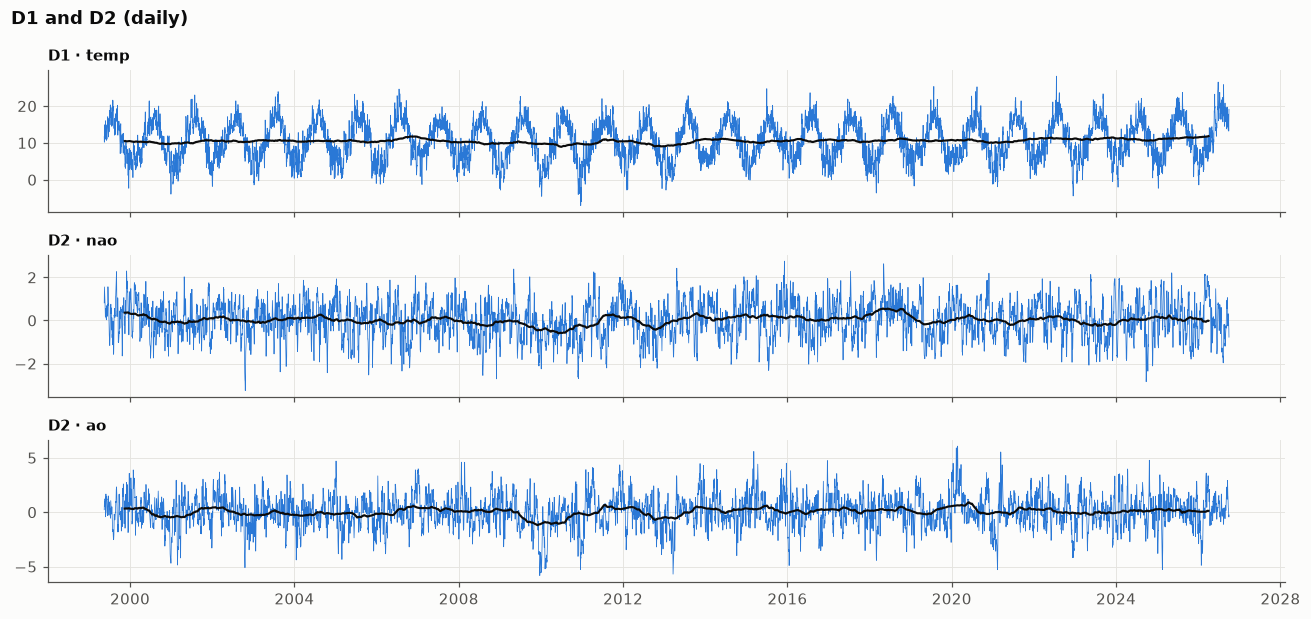

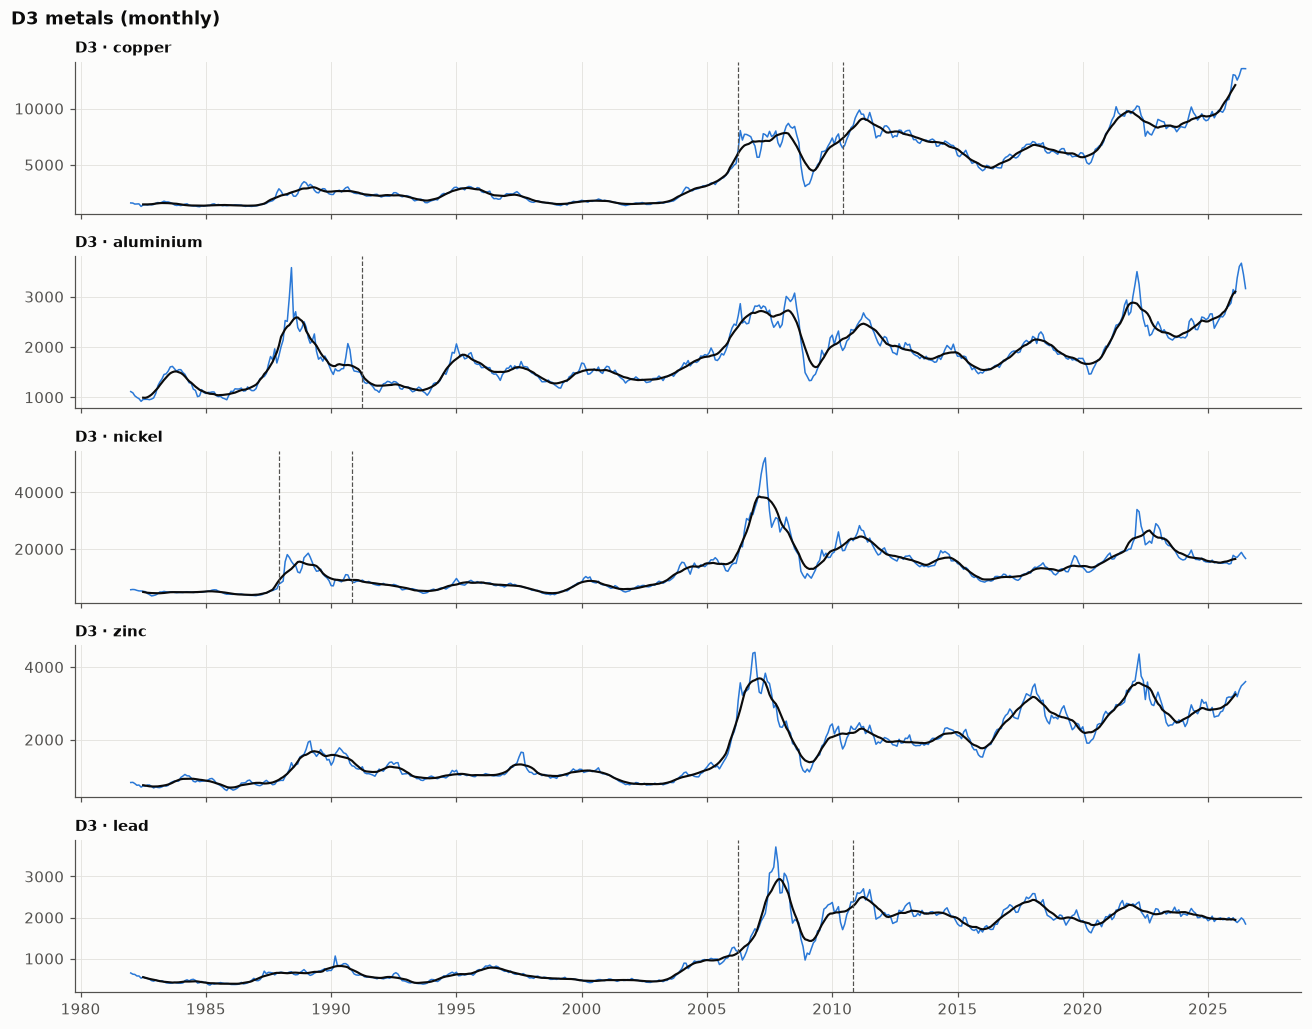

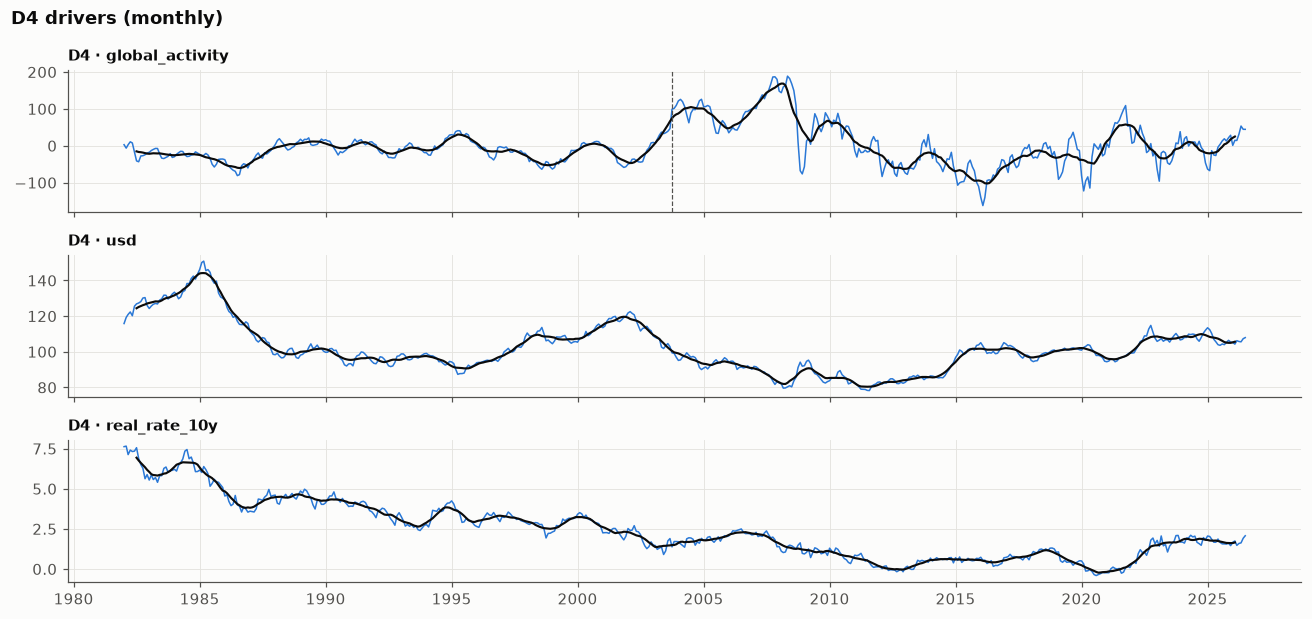

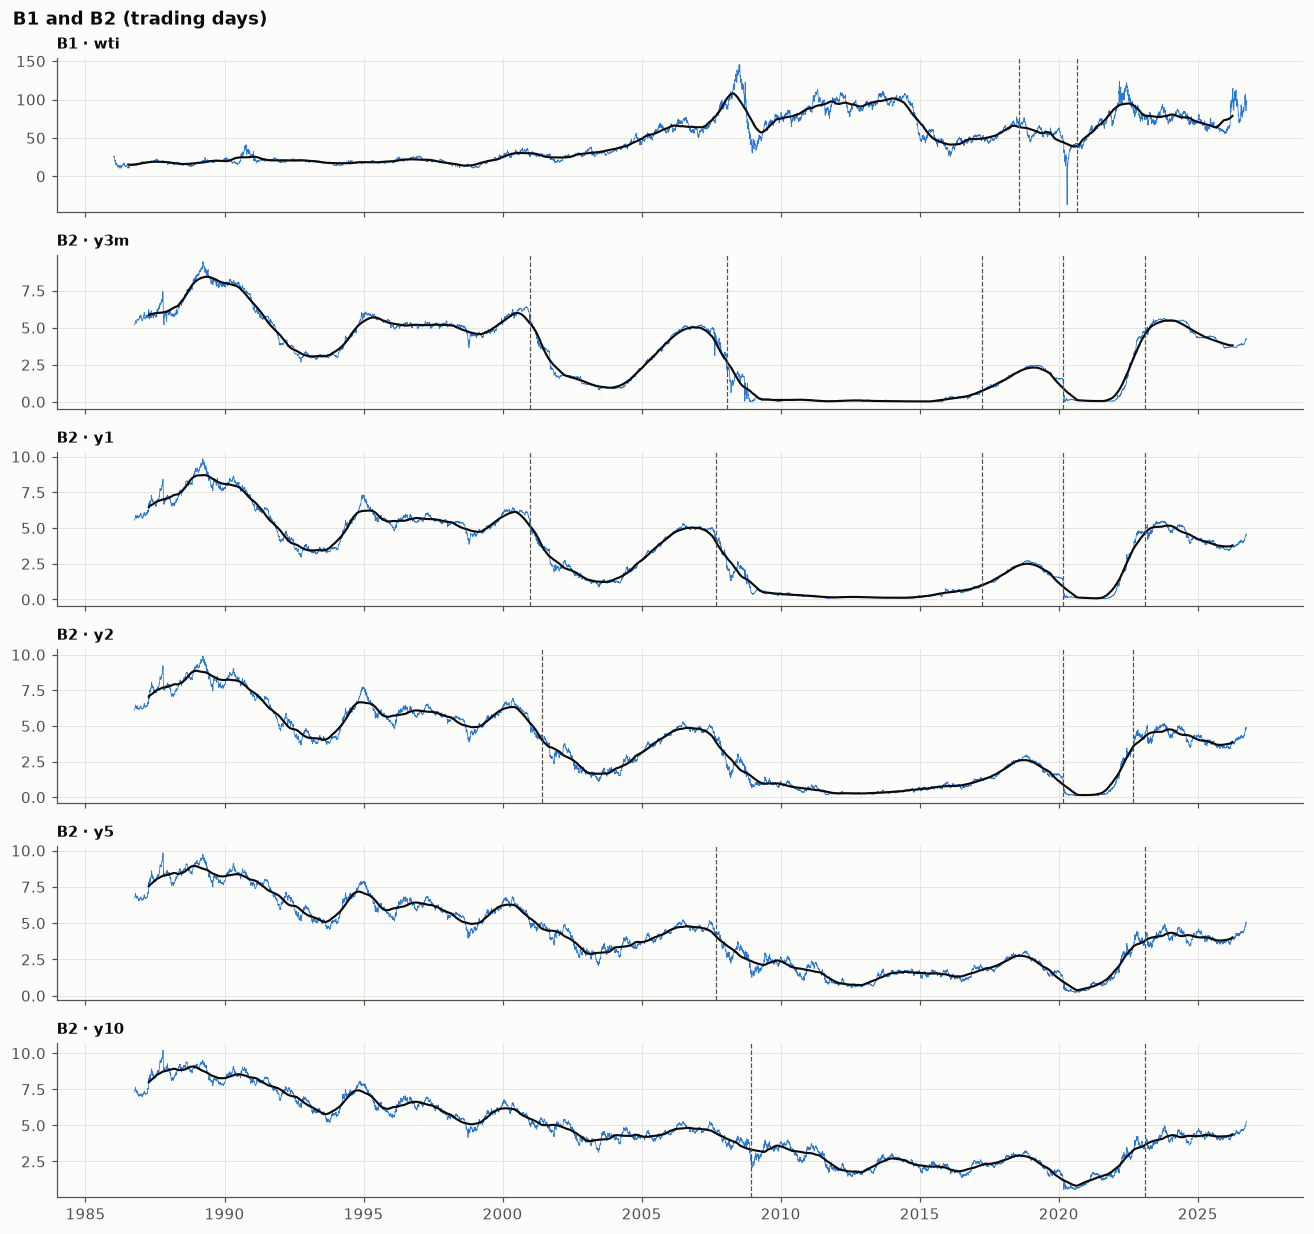

D1:temp                0 breaks: 
D2:nao                 0 breaks: 
D2:ao                  0 breaks: 
D3:copper              2 breaks: 2006-04, 2010-06
D3:aluminium           1 breaks: 1991-04
D3:nickel              2 breaks: 1987-12, 1990-11
D3:zinc                0 breaks: 
D3:lead                2 breaks: 2006-04, 2010-11
D4:global_activity     1 breaks: 2003-10
D4:usd                 0 breaks: 
D4:real_rate_10y       0 breaks: 
B1:wti                 2 breaks: 2018-08, 2020-09
B2:y3m                 5 breaks: 2001-01, 2008-02, 2017-04, 2020-03, 2023-02
B2:y1                  5 breaks: 2001-01, 2007-09, 2017-04, 2020-03, 2023-02
B2:y2                  3 breaks: 2001-06, 2020-03, 2022-09
B2:y5                  2 breaks: 2007-09, 2023-02
B2:y10                 2 breaks: 2008-12, 2023-02


In [21]:
def monthly_for_breaks(s, grain):
    m = (s.resample("MS").mean() if grain != "monthly" else s).dropna()
    if s.name == "temp":   # remove the average annual cycle first
        m = m - m.groupby(m.index.month).transform("mean")
    elif (m > 0).all():    # prices, yields, indices: compare log changes
        m = np.log(m)
    return m

groups = {"D1 and D2 (daily)": [("D1", "temp"), ("D2", "nao"), ("D2", "ao")],
          "D3 metals (monthly)": [("D3", m) for m in METALS],
          "D4 drivers (monthly)": [("D4", d) for d in DRIVERS],
          "B1 and B2 (trading days)": [("B1", "wti")] + [("B2", c) for c in TREASURY]}
breaks = {}
for title, members in groups.items():
    fig, axes = plt.subplots(len(members), 1, figsize=(12, 1.9 * len(members)), sharex=True)
    for ax, (d, c) in zip(np.atleast_1d(axes), members):
        s = SNAP[d][c].dropna()
        grain = DATASETS[d]["grain"]
        win = 12 if grain == "monthly" else (252 if grain == "trading day" else 365)
        ax.plot(s.index, s, color=COLORS[0], lw=0.5 if len(s) > 2000 else 1.0)
        ax.plot(s.index, s.rolling(win, center=True).mean(), color=INK, lw=1.4)
        m = monthly_for_breaks(s, grain)
        breaks[f"{d}:{c}"] = pelt_breaks(m.to_numpy(), m.index)
        for b in breaks[f"{d}:{c}"]:
            ax.axvline(b, color=INK_2, ls="--", lw=0.8)
        ax.set_title(f"{d} · {c}", loc="left", fontsize=10)
    fig.suptitle(title, x=0.01, ha="left", fontweight="bold")
    fig.tight_layout()
    fig.savefig(RESULTS / "figures" / f"fig_ch03_01_trends_{title.split()[0]}.png", dpi=150)
    plt.show()
for k, v in breaks.items():
    print(f"{k:22s} {len(v)} breaks: {', '.join(f'{b:%Y-%m}' for b in v[:8])}{' ...' if len(v) > 8 else ''}")

**What this tells us.** PELT finds no break in the changes of temperature, NAO, AO, zinc, the dollar or the real
rate. Copper and lead break in April 2006 and again in mid-2010, around the boom and bust of 2006 to 2010, when
their monthly changes were far more volatile. Nickel breaks in December 1987 and November 1990, on either side of
its 1988 to 1990 spike, and WTI in August 2018 and September 2020. The short-term yields break five times: near
the start of the rate-cutting cycles of 2001 and of 2007 to 2008, in 2017, in March 2020 and in early 2023, as the
volatility of their daily changes shifted with monetary policy.

## 10 · Persistence: ACF and PACF

The autocorrelation function (ACF) shows how strongly a series is correlated with itself $k$ steps back:

$$\hat\rho_k = \frac{\sum_{t=k+1}^{n}(x_t - \bar x)(x_{t-k} - \bar x)}{\sum_{t=1}^{n} (x_t - \bar x)^2}.$$

The partial autocorrelation $\hat\phi_{kk}$ (PACF) is the correlation at lag $k$ after removing what the shorter
lags already explain; it equals the last coefficient of an AR($k$) model fitted to the series. The shaded band is
$\pm 1.96/\sqrt{n}$, the approximate 95 % range for a series with no correlation at all (white noise).

How to read the plots: an ACF that decays slowly points to a trend, a unit root or long memory; spikes at the
seasonal lag point to seasonality; and a PACF that drops to zero after lag $p$ suggests an AR model of order $p$.

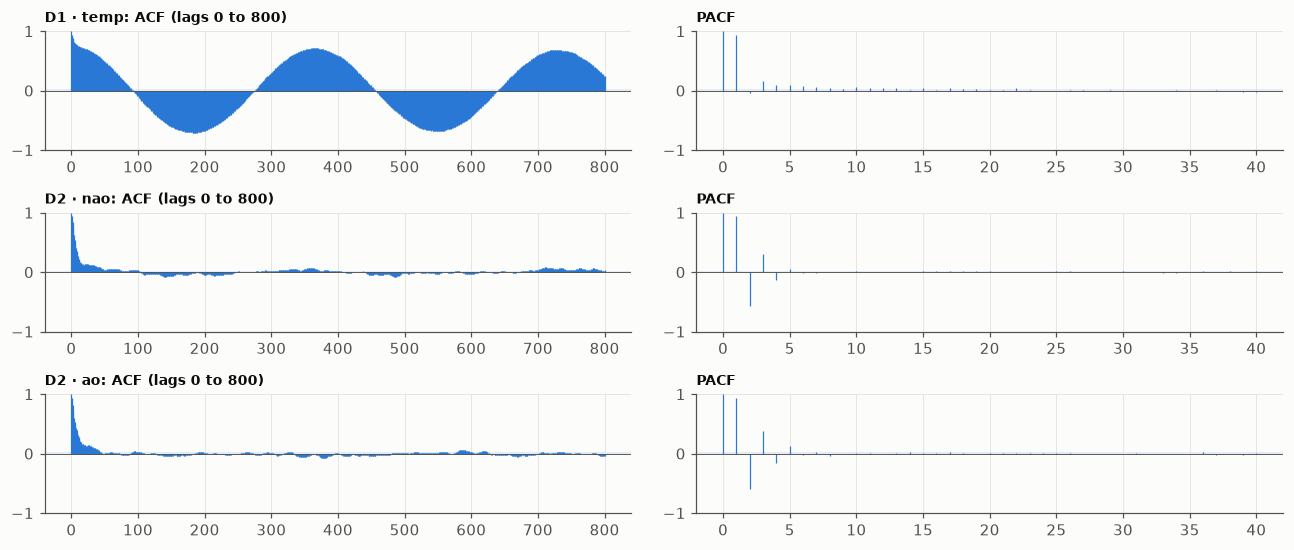

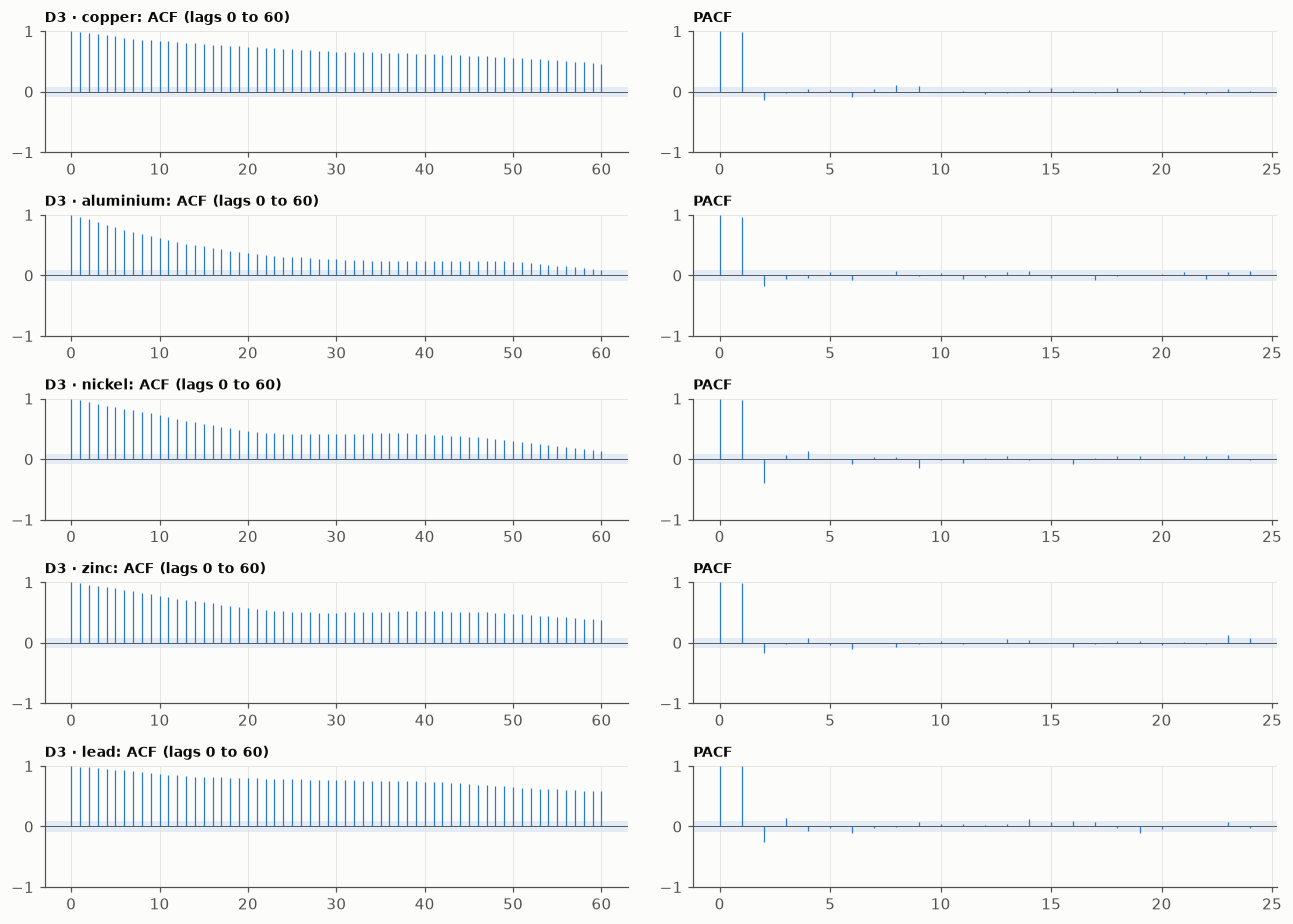

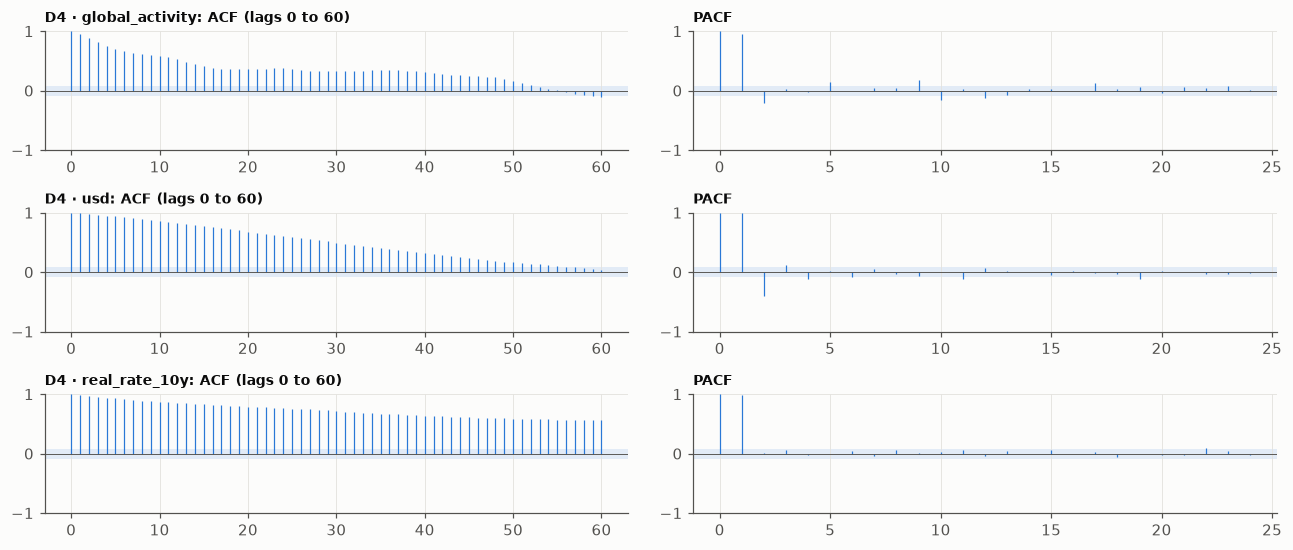

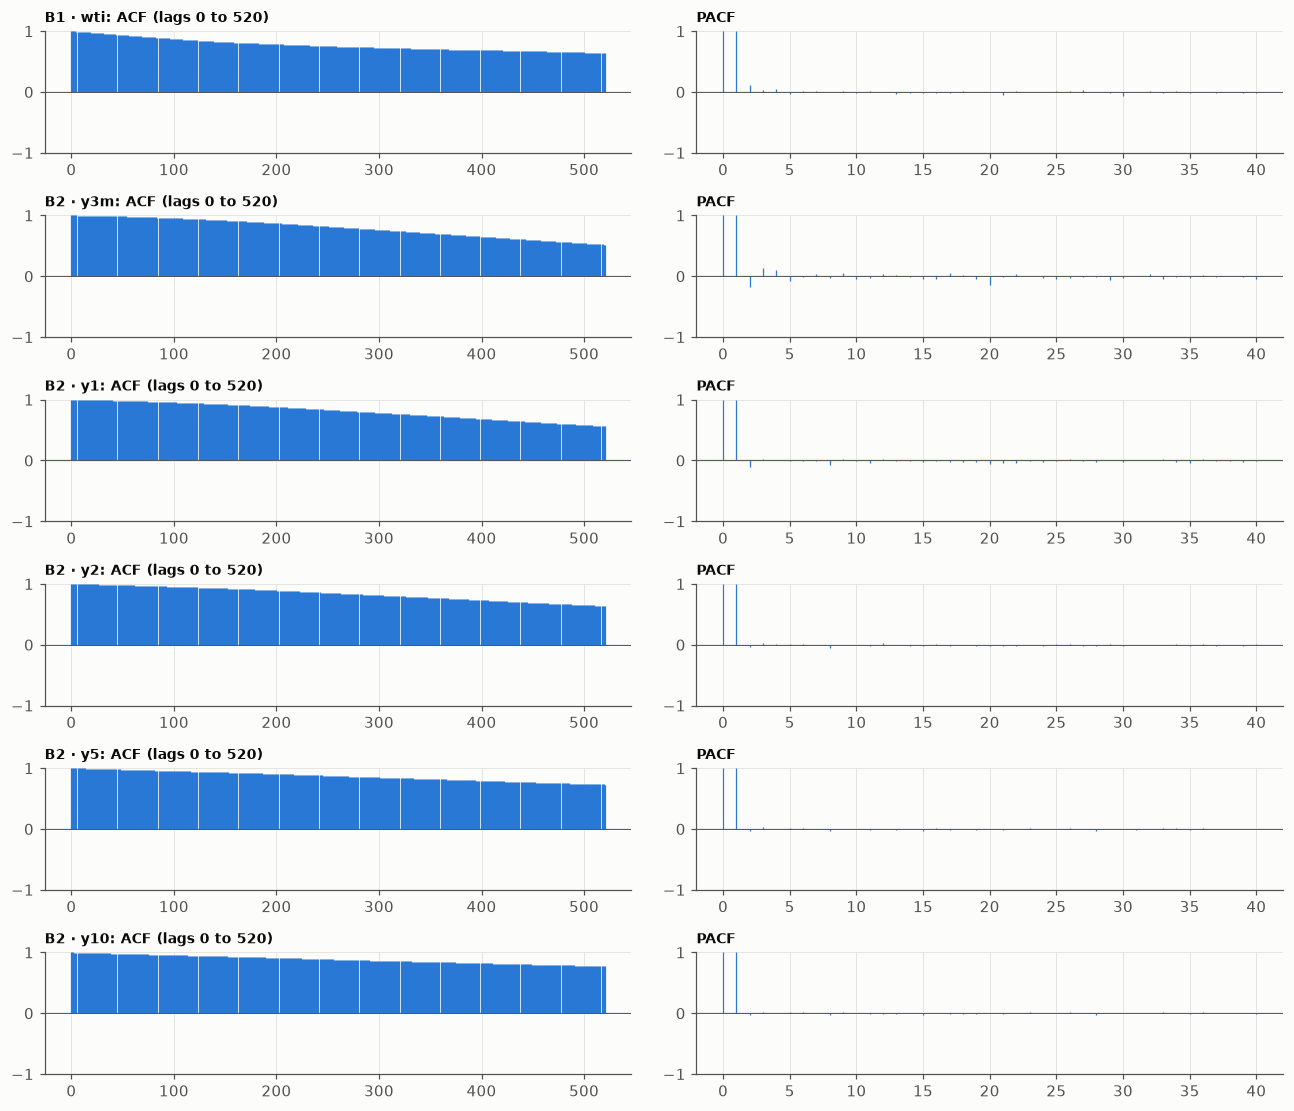

In [22]:
from statsmodels.tsa.stattools import acf, pacf

for title, members in groups.items():
    fig, axes = plt.subplots(len(members), 2, figsize=(12, 1.7 * len(members)), squeeze=False)
    for (ax1, ax2), (d, c) in zip(axes, members):
        x = SNAP[d][c].dropna().to_numpy()
        grain = DATASETS[d]["grain"]
        long_lag = {"daily": 800, "trading day": 520, "monthly": 60}[grain]
        r, p = acf(x, nlags=long_lag, fft=True), pacf(x, nlags=40 if grain != "monthly" else 24)
        band = 1.96 / np.sqrt(len(x))
        for ax, vals in [(ax1, r), (ax2, p)]:
            ax.vlines(np.arange(len(vals)), 0, vals, color=COLORS[0], lw=0.8)
            ax.axhspan(-band, band, color=COLORS[0], alpha=0.12, lw=0)
            ax.axhline(0, color=INK_2, lw=0.6)
            ax.set_ylim(-1, 1)
        ax1.set_title(f"{d} · {c}: ACF (lags 0 to {long_lag})", loc="left", fontsize=9)
        ax2.set_title("PACF", loc="left", fontsize=9)
    fig.tight_layout()
    fig.savefig(RESULTS / "figures" / f"fig_ch03_01_acf_{title.split()[0]}.png", dpi=150)
    plt.show()

**What this tells us.** Temperature's ACF is a slow cosine with a period of 365 days (0.72 at lag 365, −0.71 at
lag 182): that is the annual cycle. Its lag-1 autocorrelation is 0.94, so today's temperature says a lot about
tomorrow's. NAO and AO forget quickly: their ACF is about 0.4 after a week and falls below 0.1 after 34 to 37 days.
For the metals, the drivers, WTI and the yields, the ACF decays slowly over the whole range shown (copper 0.46 at
60 months, WTI 0.64 at 520 trading days), the pattern of a unit root that Table 2 reports.

## 11 · Do the metals move together? (D3 and D4)

D3 treats the five metal prices as one multivariate dataset because all five are industrial metals and respond to
the same swings in global demand. We measure how strongly they move together in three ways.

#### Correlations of log prices and of log changes

Two trending series can look strongly correlated even when they have nothing to do with each other (a *spurious*
correlation), so correlations between price levels mislead. The correlations between the monthly log changes,

$$\Delta \log P_{i,t} = \log P_{i,t} - \log P_{i,t-1},$$

which are close to percentage changes, are the honest measure.

#### The common factor

Principal component analysis finds the single combination of the five log changes that captures as much of their
joint variation as possible. Its share of the total variance is $\lambda_1 / \sum_i \lambda_i$, where
$\lambda_1 \ge \dots \ge \lambda_5$ are the eigenvalues of the correlation matrix of the five log changes. If the
metals were unrelated, each component would take about a fifth, so the share would be close to 0.2.

#### Cointegration

Prices can wander a long way and still be tied together in the long run, for example when the ratio of two prices
keeps returning to a typical value. Such a long-run tie is a *cointegrating relation*, and the Johansen test
counts them. It collects the log prices in a vector $y_t$ and writes a vector error-correction model,

$$\Delta y_t = \Pi\thinspace y_{t-1} + \sum_{i=1}^{k} \Gamma_i\thinspace \Delta y_{t-i} + \mu + \varepsilon_t,$$

in which the term $\Pi\thinspace y_{t-1}$ pulls the prices back towards their long-run relations. The rank $r$ of
the matrix $\Pi$ is the number of such relations. With $\hat\mu_1 \ge \dots \ge \hat\mu_5$ the eigenvalues that
the Johansen procedure estimates (squared canonical correlations, not the PCA eigenvalues above) and $T$ the
number of observations, the trace statistic

$$\mathrm{Trace}(r) = -T \sum_{i=r+1}^{5} \log\left(1 - \hat\mu_i\right)$$

tests "at most $r$ relations" against "more than $r$". The lag order $k$ is chosen by AIC.

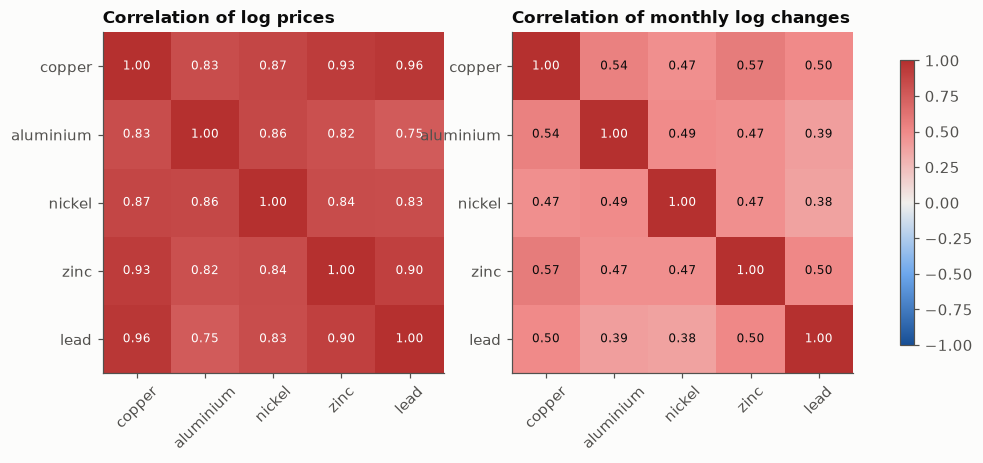

first principal component of log changes: 58.5% of the variance (0.20 if unrelated); loadings copper 0.48, aluminium 0.44, nickel 0.43, zinc 0.47, lead 0.42
pairwise correlations of log changes: 0.38 to 0.57 (median 0.48)
Johansen trace test (lags in differences k = 2): cointegration rank 3 at 5 %


,rank <=,trace,5% critical
0,0,91.1,69.8
1,1,58.0,47.9
2,2,34.8,29.8
3,3,13.5,15.5
4,4,1.2,3.8


In [23]:
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import coint_johansen

logp = np.log(SNAP["D3"][list(METALS)]).asfreq("MS")   # explicit monthly frequency for statsmodels
dlog = logp.diff().dropna()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, frame, title in [(axes[0], logp, "log prices"), (axes[1], dlog, "monthly log changes")]:
    corr = frame.corr()
    im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
    ax.set_xticks(range(5), corr.columns, rotation=45)
    ax.set_yticks(range(5), corr.columns)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr.iat[i, j]) > 0.6 else INK)
    ax.set_title(f"Correlation of {title}", loc="left")
    ax.grid(False)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(RESULTS / "figures" / "fig_ch03_01_metals_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

eig = np.linalg.eigvalsh(dlog.corr())[::-1]
loadings = np.linalg.eigh(dlog.corr())[1][:, -1]
loadings *= np.sign(loadings.sum())
print(f"first principal component of log changes: {eig[0] / eig.sum():.1%} of the variance "
      f"(0.20 if unrelated); loadings " + ", ".join(f"{m} {l:.2f}" for m, l in zip(METALS, loadings)))
off = dlog.corr().to_numpy()[np.triu_indices(5, 1)]
print(f"pairwise correlations of log changes: {off.min():.2f} to {off.max():.2f} (median {np.median(off):.2f})")

k = max(1, VAR(logp).select_order(maxlags=12).aic - 1)
jo = coint_johansen(logp, det_order=0, k_ar_diff=k)
trace = pd.DataFrame({"rank <=": range(5), "trace": jo.lr1.round(1), "5% critical": jo.cvt[:, 1].round(1)})
rank = int(np.argmax(np.append(jo.lr1 < jo.cvt[:, 1], True)))
print(f"Johansen trace test (lags in differences k = {k}): cointegration rank {rank} at 5 %")
trace

**What this tells us.** The metals do move together. The first principal component explains 58.5 % of the
variance of their monthly log changes, against about 20 % if they were unrelated. All five load on it almost
equally (0.42 to 0.48), and the pairwise correlations range from 0.38 to 0.57. The Johansen trace test finds three
cointegrating relations among the five log prices at the 5 % level, so the price levels are also tied together in
the long run, beyond the month-to-month co-movement.

### D4: the drivers next to the metals

The next table shows the same-month correlations between the metals' log changes and the changes in the three
drivers: the change in the Kilian index, the log change of the dollar index and the change in the real rate. This
is a single average over the whole sample. Notebook 02 shows when, and at which time scales, the relations hold.

In [24]:
drv = SNAP["D4"][list(DRIVERS)]
ddrv = pd.DataFrame({"global_activity": drv["global_activity"].diff(), "usd": np.log(drv["usd"]).diff(),
                     "real_rate_10y": drv["real_rate_10y"].diff()}).dropna()
cross = pd.concat([dlog, ddrv], axis=1).dropna().corr().loc[list(METALS), list(DRIVERS)]
cross.round(2)

,global_activity,usd,real_rate_10y
copper,0.15,-0.38,0.05
aluminium,0.08,-0.26,0.08
nickel,0.10,-0.25,0.05
zinc,0.04,-0.25,0.08
lead,0.07,-0.31,0.08


**What this tells us.** Of the three drivers, only the dollar moves with the metals in the same month, with
correlations of −0.25 to −0.38 (when the dollar strengthens, prices quoted in dollars fall), strongest for copper.
Changes in the Kilian index (0.04 to 0.15) and in the real rate (0.05 to 0.08) are only weakly related at this
horizon. Notebook 02 checks whether the relations are stronger over longer periods or in particular episodes.

Strong co-movement is the argument for forecasting the metals jointly: a model that reads all five together can
borrow strength from their common factor. Cointegration adds a long-run anchor that models which forecast each
series on its own (channel-independent models) cannot use. If the joint models in the forecasting notebooks do
*not* gain on D3, these numbers tell us whether that is surprising.

## Key takeaways

- The two tables describe every series with standard statistics. Each function is a direct port of the R function
  named in its docstring, so the numbers can be checked against R.
- The R-style entropy column mostly measures the length of a series; read the histogram entropy instead.
- With 10,000 daily observations nearly every test rejects its null hypothesis. The effect sizes (STL strength,
  the ACF, the DFA exponent) decide what actually matters.
- Stationarity, seasonality, memory and stability differ sharply across the six datasets, which is what makes
  them a useful test bed for zero-shot models.
- The metal prices share a strong common factor, which is the reason for the multivariate experiments.

## References

Tables 1 and 2 follow the layout of two earlier studies by the authors of this book:

- Sengupta, S., Singh, S. K., & Chakraborty, T. (2025). Uncertainty-augmented Bayesian VARs for macroeconomic forecasting: evidence from the G7. Preprint, [arXiv:2510.23347](https://arxiv.org/abs/2510.23347)
- Sengupta, S., Chakraborty, T., & Singh, S. K. (2025). Forecasting CPI inflation under economic policy and geopolitical uncertainties. *International Journal of Forecasting*, 41(3), 953–981. [doi:10.1016/j.ijforecast.2024.08.005](https://doi.org/10.1016/j.ijforecast.2024.08.005)

Methods, in the order they appear:

- Entropy (Section 1): Hausser, J., & Strimmer, K. (2009). Entropy inference and the James-Stein estimator, with application to nonlinear gene association networks. *Journal of Machine Learning Research*, 10, 1469–1484. [jmlr.org](https://www.jmlr.org/papers/v10/hausser09a.html) (the R package `entropy`)
- Miller–Madow correction (Section 1): Miller, G. A. (1955). Note on the bias of information estimates. In H. Quastler (Ed.), *Information Theory in Psychology: Problems and Methods* (pp. 95–100). Free Press. No DOI: a 1955 book chapter.
- Fourier terms (Section 1b) and seasonal strength $F_S$ (Section 4): Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3rd ed.), Sections 7.4 and 4.3. OTexts. [otexts.com/fpp3](https://otexts.com/fpp3/useful-predictors.html)
- Day length, the CBM model (Section 1b): Forsythe, W. C., Rykiel, E. J., Stahl, R. S., Wu, H., & Schoolfield, R. M. (1995). A model comparison for daylength as a function of latitude and day of year. *Ecological Modelling*, 80(1), 87–95. [doi:10.1016/0304-3800(94)00034-F](https://doi.org/10.1016/0304-3800(94)00034-F)
- Wavelets and the MODWT (Section 1b): Percival, D. B., & Walden, A. T. (2000). *Wavelet Methods for Time Series Analysis*. Cambridge University Press. [doi:10.1017/CBO9780511841040](https://doi.org/10.1017/CBO9780511841040)
- KPSS test (Section 3): Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against the alternative of a unit root. *Journal of Econometrics*, 54(1–3), 159–178. [doi:10.1016/0304-4076(92)90104-Y](https://doi.org/10.1016/0304-4076(92)90104-Y)
- Dickey–Fuller test (Section 3): Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root. *Journal of the American Statistical Association*, 74(366a), 427–431. [doi:10.1080/01621459.1979.10482531](https://doi.org/10.1080/01621459.1979.10482531)
- Combined seasonality test (Section 4): Ollech, D., & Webel, K. (2023). A random forest-based approach to combining and ranking seasonality tests. *Journal of Econometric Methods*, 12(1), 117–130. [doi:10.1515/jem-2020-0020](https://doi.org/10.1515/jem-2020-0020)
- STL (Section 4): Cleveland, R. B., Cleveland, W. S., McRae, J. E., & Terpenning, I. (1990). STL: a seasonal-trend decomposition procedure based on loess. *Journal of Official Statistics*, 6(1), 3–73. (No DOI; the R function `stats::stl` documents the same reference.)
- Seasonal strength (Section 4): Wang, X., Smith, K., & Hyndman, R. (2006). Characteristic-based clustering for time series data. *Data Mining and Knowledge Discovery*, 13(3), 335–364. [doi:10.1007/s10618-005-0039-x](https://doi.org/10.1007/s10618-005-0039-x)
- Keenan test (Section 5): Keenan, D. M. (1985). A Tukey nonadditivity-type test for time series nonlinearity. *Biometrika*, 72(1), 39–44. [doi:10.1093/biomet/72.1.39](https://doi.org/10.1093/biomet/72.1.39)
- Tsay test (Section 5): Tsay, R. S. (1986). Nonlinearity tests for time series. *Biometrika*, 73(2), 461–466. [doi:10.1093/biomet/73.2.461](https://doi.org/10.1093/biomet/73.2.461)
- BDS test (Section 5): Brock, W. A., Dechert, W. D., Scheinkman, J. A., & LeBaron, B. (1996). A test for independence based on the correlation dimension. *Econometric Reviews*, 15(3), 197–235. [doi:10.1080/07474939608800353](https://doi.org/10.1080/07474939608800353)
- Hurst exponent (Section 6): Hurst, H. E. (1951). Long-term storage capacity of reservoirs. *Transactions of the American Society of Civil Engineers*, 116(1), 770–799. [doi:10.1061/TACEAT.0006518](https://doi.org/10.1061/TACEAT.0006518)
- Small-sample correction of R/S (Section 6): Anis, A. A., & Lloyd, E. H. (1976). The expected value of the adjusted rescaled Hurst range of independent normal summands. *Biometrika*, 63(1), 111–116. [doi:10.1093/biomet/63.1.111](https://doi.org/10.1093/biomet/63.1.111)
- Detrended fluctuation analysis (Section 6): Peng, C.-K., Buldyrev, S. V., Havlin, S., Simons, M., Stanley, H. E., & Goldberger, A. L. (1994). Mosaic organization of DNA nucleotides. *Physical Review E*, 49(2), 1685–1689. [doi:10.1103/PhysRevE.49.1685](https://doi.org/10.1103/PhysRevE.49.1685)
- Studentised residuals and outlier tests (Section 7): Cook, R. D., & Weisberg, S. (1982). *Residuals and Influence in Regression*. Chapman & Hall. [University of Minnesota digital conservancy](https://hdl.handle.net/11299/37076)
- OLS-CUSUM test (Section 7): Ploberger, W., & Krämer, W. (1992). The CUSUM test with OLS residuals. *Econometrica*, 60(2), 271–285. [doi:10.2307/2951597](https://doi.org/10.2307/2951597)
- PELT (Section 7): Killick, R., Fearnhead, P., & Eckley, I. A. (2012). Optimal detection of changepoints with a linear computational cost. *Journal of the American Statistical Association*, 107(500), 1590–1598. [doi:10.1080/01621459.2012.737745](https://doi.org/10.1080/01621459.2012.737745)
- ACF and PACF (Section 10): Box, G. E. P., & Jenkins, G. M. (1976). *Time Series Analysis: Forecasting and Control* (revised ed.). Holden-Day, San Francisco. ISBN 0-8162-1104-3 (no DOI).
- Spurious correlation of trending series (Section 11): Granger, C. W. J., & Newbold, P. (1974). Spurious regressions in econometrics. *Journal of Econometrics*, 2(2), 111–120. [doi:10.1016/0304-4076(74)90034-7](https://doi.org/10.1016/0304-4076(74)90034-7)
- Johansen test (Section 11): Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive models. *Econometrica*, 59(6), 1551–1580. [doi:10.2307/2938278](https://doi.org/10.2307/2938278)
- Co-movement of commodity prices (Section 11): Pindyck, R. S., & Rotemberg, J. J. (1990). The excess co-movement of commodity prices. *The Economic Journal*, 100(403), 1173–1189. [doi:10.2307/2233966](https://doi.org/10.2307/2233966)
- Common features of metal prices (Section 11): Issler, J. V., Rodrigues, C., & Burjack, R. (2014). Using common features to understand the behavior of metal-commodity prices and forecast them at different horizons. *Journal of International Money and Finance*, 42, 310–335. [doi:10.1016/j.jimonfin.2013.08.017](https://doi.org/10.1016/j.jimonfin.2013.08.017)